# Full replication of *InferSent*
## Supervised Learning of Universal Sentence Representations from Natural Language Inference Data
**Conneau, Kiela, Schwenk, Barrault, Bordes — EMNLP 2017** · Advanced Topics in ML mini project

### What is reproduced (paper → notebook section)
| Paper item | What it is | Section |
|---|---|---|
| Sec. 3.3 | SNLI training recipe (SGD, lr 0.1, decay 0.99, ÷5 on plateau, batch 64, GloVe 840B fixed) | §3–§4 |
| **Table 3**, Fig. 5 | 7 encoders; embedding-size study | §3, §10 |
| **Table 4** | transfer on MR, CR, SUBJ, MPQA, SST, TREC, MRPC, SICK-R, SICK-E, STS14 (SentEval) for BiLSTM-Max trained on **SNLI / AllNLI / SST**, the **untrained** BiLSTM-Max and the **BOW baselines** (GloVe, positional encoding, fastText, word2vec) | §5, §7, §10 |
| **Table 5** | COCO caption/image retrieval with ResNet-101 features | §6 |
| Sec. 5.1 | Adam vs SGD observation | §4 (`OPTIMIZER='adam'`), §10 |
| Appendix Figs. 6–9 | what max-pooling selects, trained vs untrained | §11 |
| rows copied from other papers (SkipThought, FastSent, SIF, AdaSent …) | cannot be re-run here | printed as *reference rows* in §10 |

### One notebook = one experiment (edit `CFG`, press *Save & Run All*)
Every run saves small result files (`results_<TAG>.json`) to `outputs/`; **§10 collects all of them** (also from earlier runs attached as Kaggle inputs) into the paper's tables. Times below are for a Kaggle T4; only the first row was measured, the others are estimates.

| # | Experiment | `CFG` edits | est. time |
|---|---|---|---|
| 1 | **Main InferSent** (Table 3/4 row, Table 5) | defaults (+ `RUN_COCO=True` for Table 5) | ≈ 4.6 h (measured) |
| 2 | Table 3 other encoders | `ARCH='LSTM'`, `'GRU'`, `'BiGRU-last'`, `'BiLSTM-Mean'`, `'Inner-attention'`, `'HConvNet'` (tip: `MAX_EPOCHS=6`, `SENTEVAL_KFOLD=5`) | ≈ 2–4 h each |
| 3 | Fig. 5 | `ARCH='BiLSTM-Max'`, `ENC_DIM=512 / 1024 / 2048` | ≈ 1.5–3 h each |
| 4 | Table 4 row *on AllNLI* | `TRAIN_DATA='AllNLI'` | ≈ 7–8 h |
| 5 | Table 4 row *on SST* | `TRAIN_DATA='SST'` | ≈ 3 h |
| 6 | Table 4 untrained + BOW rows | `SKIP_MAIN=True`, `RUN_BASELINES=True` | ≈ 3 h |
| 7 | Sec. 5.1 Adam vs SGD | `OPTIMIZER='adam'` | ≈ 4 h |
| 8 | **Improvement experiments** (below) | see next box | varies |

### Improvements beyond a literal replication (all **off** by default → default = faithful replication)
After reading the full paper I found places where a literal reading differs from my first version, and a few cheap ways to push results further. Each one is a switch, and its result is saved under its own tag so you can compare against the faithful run in §10:

1. **Fidelity fixes (try first — aims to close the gap to the paper):** `FC_STYLE='mlp1'` (paper text: *1 hidden layer of 512 units*) and `LR_RULE='prev'` (paper text: divide lr by 5 *if dev accuracy decreases*).
2. **Train on AllNLI** (`TRAIN_DATA='AllNLI'`) — the paper's own stronger model (Table 4: e.g. MR 79.9→81.1, CR 84.6→86.3).
3. **Dropout on the classifier input** (`DROPOUT=0.1…0.3`) — our model reaches 93% train vs 84% dev accuracy on SNLI (over-fitting). *Not in the paper; may raise SNLI accuracy, but the paper warns that this can hurt transfer.*
4. **Concatenated embeddings** (`RUN_ENSEMBLE=True`): BiLSTM-Max ⊕ BiGRU-last ⊕ GloVe-BOW. No retraining, only a transfer run; larger features usually help logistic regression (paper Sec. 5.1, Fig. 5).
5. **Multiple seeds** (`SEED=…`) to report mean ± std instead of one number.

> Improvements are experiments, not guarantees: a result may go up, stay the same or go down, and the honest report is the comparison table in §10.

In [1]:
# ============================================================
# 0. IMPORTS, CONFIG, REPRODUCIBILITY
# ============================================================
import os, sys, re, json, time, random, glob, zipfile, subprocess, warnings, pickle, shutil
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence, pad_sequence
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from IPython.display import display

# ------------------------- CONFIG --------------------------
CFG = dict(
    # ---------- which experiment ----------
    ARCH         = 'BiLSTM-Max',   # 'LSTM','GRU','BiGRU-last','BiLSTM-Mean','Inner-attention','HConvNet','BiLSTM-Max'
    ENC_DIM      = None,           # None -> paper default (2048 for LSTM, 4096 otherwise); 512/1024/2048 for Fig. 5
    TRAIN_DATA   = 'SNLI',         # 'SNLI' | 'AllNLI' (SNLI + MultiNLI) | 'SST' (single-sentence sentiment, Table 4 row "on SST")
    SKIP_MAIN    = False,          # True: do NOT train/evaluate a model (use for baselines / ensembles / aggregation only)
    # ---------- paper-faithful training recipe ----------
    FC_DIM       = 512,
    BATCH_SIZE   = 64,
    LR           = 0.1,            # SGD, no momentum
    LR_DECAY     = 0.99,           # lr *= 0.99 every epoch (from epoch 2)
    LR_SHRINK    = 5.0,            # lr /= 5 on a dev-accuracy plateau
    MIN_LR       = 1e-5,           # stop when lr < 1e-5
    GRAD_CLIP    = 5.0,
    # ---------- IMPROVEMENT / ABLATION SWITCHES (defaults = faithful replication) ----------
    FC_STYLE     = 'linear3',      # 'linear3' = authors' released code | 'mlp1' = paper text (1 hidden layer of 512, tanh)
    LR_RULE      = 'best',         # 'best': shrink if dev <= best so far (released code) | 'prev': shrink if dev < previous epoch (paper wording)
    DROPOUT      = 0.0,            # >0: dropout on classifier input (NOT in the paper)
    OPTIMIZER    = 'sgd',          # 'sgd' (paper) | 'adam' (Sec. 5.1 comparison)
    ADAM_LR      = 1e-3,
    # ---------- compute budget ----------
    MAX_EPOCHS   = 25,
    TIME_LIMIT_HOURS = 10.0,       # graceful stop before Kaggle's 12 h limit
    USE_AMP      = True,           # fp16 autocast (~2x faster on T4); False = strict fp32
    SEED         = 1234,
    TRAIN_SUBSET = None,           # e.g. 20000 for a smoke test of the whole pipeline
    # ---------- evaluation ----------
    RUN_TRANSFER   = True,         # SentEval transfer evaluation of the trained model (Table 4)
    REUSE_RESULTS  = True,         # if results_<TAG>.json already has a transfer result (current outputs or attached input) -> don't recompute
    SENTEVAL_KFOLD = 10,           # 10 = paper protocol; 5 = ~2x faster
    RUN_COCO       = False,        # Table 5 (needs ~2 GB COCO features download, ~1 h)
    COCO_TAGS      = None,         # None -> [TAG]; or list of trained tags, e.g. ['BiLSTM-Max_4096', 'BiLSTM-Max_4096_AllNLI']
    RUN_BASELINES  = False,        # untrained BiLSTM-Max + GloVe BOW + GloVe positional encoding (Table 4)
    RUN_BOW_EXTRA  = False,        # also fastText / word2vec BOW (extra downloads)
    RUN_ENSEMBLE   = False,        # improvement 4: concatenated embeddings
    ENSEMBLE_ITEMS = ['BiLSTM-Max_4096', 'BiGRU-last_4096', 'GloVe-BOW'],   # trained tags (need *_best.pt) and/or 'GloVe-BOW'
    ENSEMBLE_KFOLD = 5,
    TAG          = None,
)
DEFAULT_DIM = {'LSTM':2048,'GRU':4096,'BiGRU-last':4096,'BiLSTM-Mean':4096,
               'Inner-attention':4096,'HConvNet':4096,'BiLSTM-Max':4096}
assert CFG['ARCH'] in DEFAULT_DIM and CFG['TRAIN_DATA'] in ('SNLI', 'AllNLI', 'SST')
assert CFG['FC_STYLE'] in ('linear3', 'mlp1') and CFG['LR_RULE'] in ('best', 'prev') and CFG['OPTIMIZER'] in ('sgd', 'adam')
if CFG['ENC_DIM'] is None: CFG['ENC_DIM'] = DEFAULT_DIM[CFG['ARCH']]

def make_tag(c):
    t = f"{c['ARCH']}_{c['ENC_DIM']}"
    if c['TRAIN_DATA'] != 'SNLI': t += '_' + c['TRAIN_DATA']
    if c['OPTIMIZER'] != 'sgd':   t += '_adam'
    if c['FC_STYLE'] != 'linear3': t += '_fc' + c['FC_STYLE']
    if c['LR_RULE'] != 'best':    t += '_lr' + c['LR_RULE']
    if c['DROPOUT'] > 0:          t += f"_do{c['DROPOUT']}"
    return t
if CFG['TAG'] is None: CFG['TAG'] = make_tag(CFG)
TAG = CFG['TAG']

# ------------------------- PATHS ---------------------------
ON_KAGGLE = os.path.exists('/kaggle')
WORK     = '/kaggle/working' if ON_KAGGLE else os.path.abspath('./work')
OUT_DIR  = f'{WORK}/outputs'          # only small files (checkpoints, json, png, csv) -> saved with the notebook version
DATA_DIR = '/kaggle/temp/data' if ON_KAGGLE else f'{WORK}/data'     # big downloads (GloVe 5 GB, datasets): NOT saved as output
try:
    os.makedirs(DATA_DIR, exist_ok=True)
except OSError:
    DATA_DIR = '/tmp/data'; os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(CFG['SEED'])

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device :', device, '|', torch.cuda.get_device_name(0) if device.type=='cuda' else 'NO GPU - enable one in Kaggle settings!')
print('Torch  :', torch.__version__)
print('Run tag:', TAG)
print(json.dumps({k: v for k, v in CFG.items()}, indent=1))

Device : cuda | Tesla T4
Torch  : 2.11.0+cu128
Run tag: BiLSTM-Max_4096
{
 "ARCH": "BiLSTM-Max",
 "ENC_DIM": 4096,
 "TRAIN_DATA": "SNLI",
 "SKIP_MAIN": false,
 "FC_DIM": 512,
 "BATCH_SIZE": 64,
 "LR": 0.1,
 "LR_DECAY": 0.99,
 "LR_SHRINK": 5.0,
 "MIN_LR": 1e-05,
 "GRAD_CLIP": 5.0,
 "FC_STYLE": "linear3",
 "LR_RULE": "best",
 "DROPOUT": 0.0,
 "OPTIMIZER": "sgd",
 "ADAM_LR": 0.001,
 "MAX_EPOCHS": 25,
 "TIME_LIMIT_HOURS": 10.0,
 "USE_AMP": true,
 "SEED": 1234,
 "TRAIN_SUBSET": null,
 "RUN_TRANSFER": true,
 "REUSE_RESULTS": true,
 "SENTEVAL_KFOLD": 10,
 "RUN_COCO": false,
 "COCO_TAGS": null,
 "RUN_BASELINES": false,
 "RUN_BOW_EXTRA": false,
 "RUN_ENSEMBLE": false,
 "ENSEMBLE_ITEMS": [
  "BiLSTM-Max_4096",
  "BiGRU-last_4096",
  "GloVe-BOW"
 ],
 "ENSEMBLE_KFOLD": 5,
 "TAG": "BiLSTM-Max_4096"
}


In [2]:
# ============================================================
# 1. HELPERS (download, result files) + SENTEVAL SETUP
# ============================================================
def download(url, dest):
    if os.path.exists(dest) and os.path.getsize(dest) > 0:
        return dest
    os.makedirs(os.path.dirname(dest), exist_ok=True)
    print('Downloading', url)
    r = subprocess.run(['wget', '-nv', '-O', dest, url])
    if r.returncode != 0:
        if os.path.exists(dest): os.remove(dest)
        raise RuntimeError(f'Download failed: {url}  (is Internet turned ON in the Kaggle sidebar?)')
    return dest

def find_file(name):
    '''file in outputs/ or in any attached Kaggle input (e.g. output of an earlier run).'''
    p = f'{OUT_DIR}/{name}'
    if os.path.exists(p): return p
    c = glob.glob(f'/kaggle/input/**/{name}', recursive=True)
    return c[0] if c else None
find_ckpt = find_file

def find_results(name):
    p = find_file(f'results_{name}.json')
    return json.load(open(p)) if p else None

def save_results(name, **fields):
    '''merge `fields` into results_<name>.json (keeps transfer / coco results of earlier runs)'''
    cur = find_results(name) or {}
    cur.update(fields)
    json.dump(cur, open(f'{OUT_DIR}/results_{name}.json', 'w'), indent=1, default=str)
    return cur

# ---------------- SentEval: clone + compatibility patches ----------------
SENTEVAL_DIR = f'{DATA_DIR}/SentEval'
if not os.path.exists(SENTEVAL_DIR):
    subprocess.run(['git', 'clone', '-q', 'https://github.com/facebookresearch/SentEval.git', SENTEVAL_DIR], check=True)
sys.path.insert(0, SENTEVAL_DIR)
_p = f'{SENTEVAL_DIR}/senteval/sts.py'              # numpy>=1.24: ragged arrays need dtype=object
_t = open(_p).read()
for _v in ('sent1', 'sent2'):
    _t = _t.replace(f"np.array([s.split() for s in {_v}])[not_empty_idx]", f"np.array([s.split() for s in {_v}], dtype=object)[not_empty_idx]")
open(_p, 'w').write(_t)
import senteval
import inspect
inspect.getargspec = inspect.getfullargspec    # SentEval uses getargspec, removed in Python >= 3.11
TASK_PATH = f'{SENTEVAL_DIR}/data'                 # SentEval expects <TASK_PATH>/downstream/<TASK>
DS = f'{TASK_PATH}/downstream'
NEEDED = ['CR', 'MR', 'MPQA', 'SUBJ', 'SST/binary', 'TREC', 'MRPC', 'SICK', 'STS/STS14-en-test']

def have_data():
    return all(os.path.exists(f'{DS}/{n}') for n in NEEDED)

def adopt(folder):
    subprocess.run(f'cp -rn "{folder}"/* "{DS}"/', shell=True)

if not have_data():   # (1) Kaggle input dataset holding SentEval's `downstream` folder
    for cand in glob.glob('/kaggle/input/**/downstream', recursive=True):
        if os.path.isdir(f'{cand}/MR'): adopt(cand); break
if not have_data():   # (2) official script (COCO features skipped here; they are fetched in section 6)
    print('Running SentEval get_transfer_data.bash (a few minutes) ...')
    subprocess.run('apt-get -qq install -y cabextract unzip > /dev/null 2>&1', shell=True)
    txt = open(f'{DS}/get_transfer_data.bash').read()
    txt = txt.replace('curl -Lo $data_path/COCO/$split.pkl $COCO/$split.pkl', 'true')
    open(f'{DS}/get_transfer_data_nococo.bash', 'w').write(txt)
    subprocess.run(f'cd {DS} && bash get_transfer_data_nococo.bash > {OUT_DIR}/senteval_download.log 2>&1', shell=True)
if not have_data():   # (3) fallback mirror (HuggingFace, used by the SimCSE project)
    print('Official script incomplete -> trying fallback mirror ...')
    tarp = download('https://huggingface.co/datasets/princeton-nlp/datasets-for-simcse/resolve/main/senteval.tar', f'{DATA_DIR}/senteval.tar')
    subprocess.run(f'mkdir -p {DATA_DIR}/senteval_tmp && tar -xf {tarp} -C {DATA_DIR}/senteval_tmp', shell=True)
    for root, dirs, _ in os.walk(f'{DATA_DIR}/senteval_tmp'):
        if 'MR' in dirs and 'CR' in dirs: adopt(root); break
missing = [n for n in NEEDED if not os.path.exists(f'{DS}/{n}')]
print('SentEval datasets missing:', missing if missing else 'none  ✓')
assert not missing, ('Some SentEval datasets could not be downloaded (see outputs/senteval_download.log). '
                     'Upload SentEval\'s "downstream" folder as a Kaggle dataset; it is auto-detected.')

/kaggle/temp/data/SentEval/senteval/utils.py:62: SyntaxWarning: invalid escape sequence '\d'
  assert re.match("^[+-]?(\d+(\.\d*)?|\.\d+)$", split[1]) is not None


Running SentEval get_transfer_data.bash (a few minutes) ...
Official script incomplete -> trying fallback mirror ...
SentEval datasets missing: none  ✓


2026-10-10 09:13:33 URL:https://us.gcp.cdn.hf.co/xet-bridge-us/621ffdd236468d709f183d48/88d56ab28dbc96b9b8895a39ecdcf8211ed8a2942ee7bc33b79421ff27c5a841?response-content-disposition=inline%3B+filename*%3DUTF-8%27%27senteval.tar%3B+filename%3D%22senteval.tar%22%3B&user_id=public&X-Xet-Cas-Uid=public&xip=Eub0IULfEJ0&response-content-type=application%2Fx-tar&Expires=1791627211&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5nY3AuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNjIxZmZkZDIzNjQ2OGQ3MDlmMTgzZDQ4Lzg4ZDU2YWIyOGRiYzk2YjliODg5NWEzOWVjZGNmODIxMWVkOGEyOTQyZWU3YmMzM2I3OTQyMWZmMjdjNWE4NDFcXD9yZXNwb25zZS1jb250ZW50LWRpc3Bvc2l0aW9uPSomdXNlcl9pZD1wdWJsaWMmWC1YZXQtQ2FzLVVpZD1wdWJsaWMmeGlwPUV1YjBJVUxmRUowJnJlc3BvbnNlLWNvbnRlbnQtdHlwZT0qIiwiQ29uZGl0aW9uIjp7IkRhdGVMZXNzVGhhbiI6eyJFcG9jaFRpbWUiOjE3OTE2MjcyMTF9fX1dfQ__&Signature=MEQCIFfpHxIPCyRb96XvRBnXovspToE6SVRlDMAn3pfchITDAiBJMRpbQ0xVZipFLglX6wUQt8Fr6C7KPDR5ELSnSJduYw__&Key-Pair-Id=01KXEF4KZ1B6FV465MAWR4M21F&Hash-Algorithm=SHA256 [89825280/89825

## 2. Data
* **SNLI** (570k pairs; 549,367 / 9,842 / 9,824) — the paper's training set. Pairs without gold label are dropped.
* **AllNLI** = SNLI + **MultiNLI** (Williams et al., 2017). *Our construction:* train = SNLI train + MNLI train; model selection (dev) = SNLI dev + MNLI matched dev; reported test = SNLI test (+ MNLI matched/mismatched accuracy reported separately).
* **SST** (binary, SentEval version) for the Table 4 row *"BiLSTM-Max (on SST)"*: the same encoder, trained as a single-sentence classifier.
* **Word vectors:** fixed **GloVe 840B-300d**; the embedding layer is never trained; out-of-vocabulary words are dropped.

In [3]:
if CFG['SKIP_MAIN']:
    print('skipped (SKIP_MAIN=True)')
else:
    # ============================================================
    # 2a. LOAD TRAINING DATA (SNLI / AllNLI / SST)
    # ============================================================
    SNLI_URL  = 'https://nlp.stanford.edu/projects/snli/snli_1.0.zip'
    MNLI_URL  = 'https://cims.nyu.edu/~sbowman/multinli/multinli_1.0.zip'
    LABELS    = {'entailment':0, 'neutral':1, 'contradiction':2}
    LABEL_NAMES = ['entailment', 'neutral', 'contradiction']

    def read_nli_jsonl(path):
        rows = []
        with open(path, encoding='utf-8') as f:
            for line in f:
                d = json.loads(line)
                if d['gold_label'] in LABELS:
                    rows.append((d['sentence1'], d['sentence2'], LABELS[d['gold_label']]))
        return rows

    def load_snli():
        local = glob.glob('/kaggle/input/**/snli_1.0_train.jsonl', recursive=True)
        try:
            if local: root = os.path.dirname(local[0])
            else:
                zp = download(SNLI_URL, f'{DATA_DIR}/snli_1.0.zip')
                with zipfile.ZipFile(zp) as z: z.extractall(DATA_DIR)
                root = f'{DATA_DIR}/snli_1.0'
            return {s: read_nli_jsonl(f'{root}/snli_1.0_{s}.jsonl') for s in ['train', 'dev', 'test']}
        except Exception as e:
            print('Primary SNLI source failed (', e, ') -> HuggingFace datasets')
            from datasets import load_dataset
            ds = load_dataset('stanfordnlp/snli')
            return {s: [(r['premise'], r['hypothesis'], r['label']) for r in ds[h] if r['label'] in (0, 1, 2)]
                    for s, h in [('train', 'train'), ('dev', 'validation'), ('test', 'test')]}

    def load_mnli():
        local = glob.glob('/kaggle/input/**/multinli_1.0_train.jsonl', recursive=True)
        try:
            if local: root = os.path.dirname(local[0])
            else:
                zp = download(MNLI_URL, f'{DATA_DIR}/multinli_1.0.zip')
                with zipfile.ZipFile(zp) as z: z.extractall(DATA_DIR)
                root = f'{DATA_DIR}/multinli_1.0'
            return {'train': read_nli_jsonl(f'{root}/multinli_1.0_train.jsonl'),
                    'matched': read_nli_jsonl(f'{root}/multinli_1.0_dev_matched.jsonl'),
                    'mismatched': read_nli_jsonl(f'{root}/multinli_1.0_dev_mismatched.jsonl')}
        except Exception as e:
            print('Primary MultiNLI source failed (', e, ') -> HuggingFace datasets')
            from datasets import load_dataset
            ds = load_dataset('nyu-mll/multi_nli')
            return {s: [(r['premise'], r['hypothesis'], r['label']) for r in ds[h] if r['label'] in (0, 1, 2)]
                    for s, h in [('train', 'train'), ('matched', 'validation_matched'), ('mismatched', 'validation_mismatched')]}

    def load_sst():
        rows = {}
        for s in ['train', 'dev', 'test']:
            out = []
            with open(f'{DS}/SST/binary/sentiment-{s}', encoding='utf-8') as f:
                for line in f:
                    sent, lab = line.strip().split('\t')
                    out.append((sent, sent, int(lab)))          # (sentence, same sentence (unused), label)
            rows[s] = out
        return rows

    EXTRA = {}                                   # additional evaluation sets
    if CFG['TRAIN_DATA'] == 'SNLI':
        snli = load_snli(); N_CLASSES = 3
        SPLITS = {'train': snli['train'], 'dev': snli['dev'], 'test': snli['test']}
    elif CFG['TRAIN_DATA'] == 'AllNLI':
        snli, mnli = load_snli(), load_mnli(); N_CLASSES = 3
        SPLITS = {'train': snli['train'] + mnli['train'], 'dev': snli['dev'] + mnli['matched'], 'test': snli['test']}
        EXTRA = {'snli_dev': snli['dev'], 'mnli_matched': mnli['matched'], 'mnli_mismatched': mnli['mismatched']}
    else:
        SPLITS = load_sst(); N_CLASSES = 2
    print({k: len(v) for k, v in SPLITS.items()}, {k: len(v) for k, v in EXTRA.items()})
    print('Example:', SPLITS['train'][0])

2026-10-10 09:15:01 URL:https://nlp.stanford.edu/projects/snli/snli_1.0.zip [94550081/94550081] -> "/kaggle/temp/data/snli_1.0.zip" [1]


{'train': 549367, 'dev': 9842, 'test': 9824} {}
Example: ('A person on a horse jumps over a broken down airplane.', 'A person is training his horse for a competition.', 1)


In [4]:
if CFG['SKIP_MAIN']:
    print('skipped (SKIP_MAIN=True)')
else:
    # ============================================================
    # 2b. TOKENISATION
    # ============================================================
    from nltk.tokenize import TreebankWordTokenizer
    _tok = TreebankWordTokenizer()
    if CFG['TRAIN_DATA'] == 'SST':
        tokenize = lambda s: s.split()               # SentEval's SST files are already tokenised
    else:
        tokenize = lambda s: _tok.tokenize(s.strip())

    t0 = time.time()
    uniq = {s for rows in list(SPLITS.values()) + list(EXTRA.values()) for r in rows for s in (r[0], r[1])}
    TOK = {s: tokenize(s) for s in uniq}
    print(f'Tokenised {len(uniq):,} unique sentences in {time.time()-t0:.0f}s')

Tokenised 651,514 unique sentences in 21s


In [5]:
# ============================================================
# 2c. GloVe (840B, 300d)   -- needed by every experiment
# ============================================================
GLOVE_URL = 'https://nlp.stanford.edu/data/glove.840B.300d.zip'

def find_glove():
    c = glob.glob('/kaggle/input/**/glove.840B.300d.txt', recursive=True)
    if c: return c[0]
    path = f'{DATA_DIR}/glove.840B.300d.txt'
    if not os.path.exists(path):
        zp = download(GLOVE_URL, f'{DATA_DIR}/glove.840B.300d.zip')   # ~2 GB
        with zipfile.ZipFile(zp) as z: z.extract('glove.840B.300d.txt', DATA_DIR)
        os.remove(zp)
    return path

def load_text_vectors(path, dim=300, skip_header=False):
    words, vecs = [], []
    t0 = time.time()
    with open(path, 'r', encoding='utf-8', errors='ignore') as f:
        if skip_header: f.readline()
        for line in f:
            w, rest = line.rstrip('\n').split(' ', 1)
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter('ignore')
                    v = np.fromstring(rest, sep=' ', dtype=np.float32)
            except Exception:
                continue
            if v.shape[0] != dim: continue          # a few tokens contain spaces -> skip
            words.append(w); vecs.append(v)
    mat = np.stack(vecs); del vecs
    print(f'{os.path.basename(path)}: {len(words):,} words x {mat.shape[1]} loaded in {time.time()-t0:.0f}s')
    return {w: i for i, w in enumerate(words)}, mat

GLOVE_W2I, GLOVE = load_text_vectors(find_glove())
if 'TOK' in globals():
    n_tok = sum(len(t) for t in TOK.values()); n_hit = sum(1 for t in TOK.values() for w in t if w in GLOVE_W2I)
    print(f'GloVe coverage of training-data tokens: {100*n_hit/n_tok:.2f}%')

def glove_rows(sent):
    '''row indices of the GloVe words of a token list (bytes tokens are decoded; empty -> "." )'''
    rows = []
    for w in sent:
        if isinstance(w, bytes): w = w.decode('utf-8', 'ignore')
        r = GLOVE_W2I.get(w)
        if r is not None: rows.append(r)
    return rows or [GLOVE_W2I.get('.', 0)]

2026-10-10 09:25:44 URL:https://downloads.cs.stanford.edu/nlp/data/glove.840B.300d.zip [2176768927/2176768927] -> "/kaggle/temp/data/glove.840B.300d.zip" [1]


glove.840B.300d.txt: 2,196,017 words x 300 loaded in 127s
GloVe coverage of training-data tokens: 99.91%


In [6]:
if CFG['SKIP_MAIN']:
    print('skipped (SKIP_MAIN=True)')
else:
    # ============================================================
    # 2d. VOCAB (training words that have a GloVe vector), EMBEDDING MATRIX, DATALOADERS
    # ============================================================
    vocab_words = sorted({w for t in TOK.values() for w in t if w in GLOVE_W2I})
    word2idx = {'<pad>': 0, '<unk>': 1}
    for w in vocab_words: word2idx[w] = len(word2idx)
    EMB = np.zeros((len(word2idx), 300), dtype=np.float32)       # pad & unk rows stay zero
    for w, i in word2idx.items():
        if i >= 2: EMB[i] = GLOVE[GLOVE_W2I[w]]
    print('Vocabulary size (data ∩ GloVe):', len(word2idx))

    IDS = {}   # sentence -> index array (OOV words dropped; empty sentence -> <unk>)
    for s, toks in TOK.items():
        ids = [word2idx[w] for w in toks if w in word2idx]
        IDS[s] = np.asarray(ids if ids else [1], dtype=np.int64)

    class NLIData(Dataset):
        def __init__(self, rows):
            self.p = [IDS[r[0]] for r in rows]; self.h = [IDS[r[1]] for r in rows]
            self.y = np.asarray([r[2] for r in rows], dtype=np.int64)
        def __len__(self): return len(self.y)
        def __getitem__(self, i): return self.p[i], self.h[i], self.y[i]

    def collate(batch):
        p, h, y = zip(*batch)
        pl = torch.tensor([len(x) for x in p]); hl = torch.tensor([len(x) for x in h])
        P = pad_sequence([torch.from_numpy(x) for x in p], batch_first=True, padding_value=0)
        H = pad_sequence([torch.from_numpy(x) for x in h], batch_first=True, padding_value=0)
        return P, pl, H, hl, torch.tensor(y)

    train_rows = SPLITS['train']
    if CFG['TRAIN_SUBSET']:
        rng = random.Random(0); train_rows = rng.sample(train_rows, CFG['TRAIN_SUBSET'])
    def mk(rows, bs, shuffle=False):
        return DataLoader(NLIData(rows), batch_size=bs, shuffle=shuffle, collate_fn=collate, num_workers=2, pin_memory=True)
    train_loader = mk(train_rows, CFG['BATCH_SIZE'], True)
    dev_loader, test_loader = mk(SPLITS['dev'], 256), mk(SPLITS['test'], 256)
    extra_loaders = {k: mk(v, 256) for k, v in EXTRA.items()}
    print(f'train {len(train_rows):,} | dev {len(SPLITS["dev"]):,} | test {len(SPLITS["test"]):,} | steps/epoch {len(train_loader):,}')

Vocabulary size (data ∩ GloVe): 38980
train 549,367 | dev 9,842 | test 9,824 | steps/epoch 8,584


## 3. Models: sentence encoders + classifiers
The paper's NLI scheme: a **shared encoder** maps premise and hypothesis to $u$ and $v$; the classifier sees $[u,\,v,\,|u-v|,\,u\odot v]$ and outputs a 3-way softmax.

| Encoder (dim) | Definition |
|---|---|
| LSTM (2048) / GRU (4096) | last hidden state |
| BiGRU-last (4096) | concat of last hidden states of forward and backward GRU |
| BiLSTM-Mean (4096) | mean of BiLSTM hidden states |
| **BiLSTM-Max (4096)** | **element-wise max over time of BiLSTM hidden states — InferSent** |
| Inner-attention (4096) | BiLSTM + self-attention with **4 views** ($u^k=\sum_t\alpha^k_t h_t$, $\alpha^k=\mathrm{softmax}_t(\bar h_t^\top u^k_w)$, $\bar h_t=\tanh(Wh_t+b_w)$), views concatenated |
| HConvNet (4096) | 4 stacked conv layers (kernel 3); max-pool each layer's output; concatenate |

*Choices the paper leaves open:* HConvNet layers have `ENC_DIM/4` channels each; in Inner-attention the BiLSTM has `ENC_DIM/8` units per direction so that 4 concatenated views give `ENC_DIM` dimensions.
**Classifier:** `FC_STYLE='linear3'` (stacked linear layers, as in the authors' released code) or `'mlp1'` (paper text: one hidden layer of 512 units, tanh).

In [7]:
# ============================================================
# 3a. SENTENCE ENCODERS (classes only - needed by every experiment)
# ============================================================
class SentenceEncoder(nn.Module):
    '''(B,T,E) padded word embeddings + lengths -> (B, enc_dim) sentence vectors.'''
    def __init__(self, arch, emb_dim=300, enc_dim=4096):
        super().__init__()
        self.arch, self.enc_dim = arch, enc_dim
        if arch == 'LSTM':
            self.rnn = nn.LSTM(emb_dim, enc_dim, batch_first=True)
        elif arch == 'GRU':
            self.rnn = nn.GRU(emb_dim, enc_dim, batch_first=True)
        elif arch == 'BiGRU-last':
            self.rnn = nn.GRU(emb_dim, enc_dim // 2, batch_first=True, bidirectional=True)
        elif arch in ('BiLSTM-Max', 'BiLSTM-Mean'):
            self.rnn = nn.LSTM(emb_dim, enc_dim // 2, batch_first=True, bidirectional=True)
        elif arch == 'Inner-attention':
            hd = enc_dim // 4                                                  # h_t has enc_dim/4 dims; 4 views -> enc_dim
            self.rnn = nn.LSTM(emb_dim, hd // 2, batch_first=True, bidirectional=True)
            self.att_proj  = nn.Linear(hd, hd)                                 # W, b_w
            self.att_query = nn.Parameter(torch.randn(4, hd) * 0.01)           # u_w^1 .. u_w^4
        elif arch == 'HConvNet':
            ch = enc_dim // 4
            self.convs = nn.ModuleList([nn.Conv1d(emb_dim if i == 0 else ch, ch, kernel_size=3, padding=1) for i in range(4)])
        else:
            raise ValueError(arch)

    @staticmethod
    def _mask(lengths, T, dev):
        return torch.arange(T, device=dev)[None, :] < lengths.to(dev)[:, None]          # (B,T) bool

    def states(self, emb, lengths):
        '''all hidden states (B,T,D) of the recurrent models (padding positions are zero).'''
        T = emb.size(1)
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.rnn(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=T)
        return out

    def forward(self, emb, lengths):
        B, T, _ = emb.shape
        mask = self._mask(lengths, T, emb.device)
        a = self.arch
        if a == 'HConvNet':
            x = (emb * mask[..., None].to(emb.dtype)).transpose(1, 2)   # (B,E,T), padding forced to 0
            m = mask[:, None, :].to(x.dtype)
            feats = []
            for conv in self.convs:
                x = F.relu(conv(x)) * m
                feats.append(x.max(dim=2).values)                       # max-pool over time
            return torch.cat(feats, dim=1).float()
        if a in ('LSTM', 'GRU', 'BiGRU-last'):
            packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
            _, h = self.rnn(packed)
            h = h[0] if a == 'LSTM' else h                              # (dirs, B, H)
            return h.transpose(0, 1).reshape(B, -1).float()
        out = self.states(emb, lengths)                                 # (B,T,D)
        if a == 'BiLSTM-Max':
            return out.masked_fill(~mask[..., None], float('-inf')).max(dim=1).values.float()
        if a == 'BiLSTM-Mean':
            return ((out * mask[..., None]).sum(1) / lengths.to(emb.device)[:, None].to(out.dtype)).float()
        if a == 'Inner-attention':
            u = torch.tanh(self.att_proj(out))                          # (B,T,hd)  keys
            score = (u @ self.att_query.to(u.dtype).t()).masked_fill(~mask[..., None], float('-inf'))   # (B,T,4)
            alpha = torch.softmax(score.float(), dim=1).to(out.dtype)
            views = torch.einsum('btv,btd->bvd', alpha, out)            # (B,4,hd)
            return views.reshape(B, -1).float()

def make_classifier(in_dim, fc_dim, n_classes, style, dropout):
    layers = [nn.Dropout(dropout)] if dropout > 0 else []
    if style == 'linear3':      # authors' released code
        layers += [nn.Linear(in_dim, fc_dim), nn.Linear(fc_dim, fc_dim), nn.Linear(fc_dim, n_classes)]
    else:                       # paper text: 1 hidden layer of fc_dim units
        layers += [nn.Linear(in_dim, fc_dim), nn.Tanh()] + ([nn.Dropout(dropout)] if dropout > 0 else []) + [nn.Linear(fc_dim, n_classes)]
    return nn.Sequential(*layers)

class NLINet(nn.Module):
    '''premise/hypothesis -> 3-way NLI  (features [u, v, |u-v|, u*v])'''
    def __init__(self, arch, emb_matrix, enc_dim, fc_dim=512, fc_style='linear3', dropout=0.0, n_classes=3):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(torch.from_numpy(emb_matrix), freeze=True, padding_idx=0)   # fixed GloVe
        self.encoder = SentenceEncoder(arch, emb_matrix.shape[1], enc_dim)
        self.classifier = make_classifier(4 * enc_dim, fc_dim, n_classes, fc_style, dropout)
    def encode(self, ids, lengths):
        return self.encoder(self.embedding(ids), lengths)
    def forward(self, p, pl, h, hl):
        u, v = self.encode(p, pl), self.encode(h, hl)
        return self.classifier(torch.cat([u, v, (u - v).abs(), u * v], dim=1))

class SSTNet(nn.Module):
    '''single-sentence classifier (Table 4 row "BiLSTM-Max on SST"): same encoder, classifier on u only'''
    def __init__(self, arch, emb_matrix, enc_dim, fc_dim=512, dropout=0.0, n_classes=2):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(torch.from_numpy(emb_matrix), freeze=True, padding_idx=0)
        self.encoder = SentenceEncoder(arch, emb_matrix.shape[1], enc_dim)
        self.classifier = make_classifier(enc_dim, fc_dim, n_classes, 'mlp1', dropout)
    def encode(self, ids, lengths):
        return self.encoder(self.embedding(ids), lengths)
    def forward(self, p, pl, h=None, hl=None):
        return self.classifier(self.encode(p, pl))

# ---- quick sanity test of ALL encoders on random data (seconds; catches shape / padding bugs) ----
_emb = torch.randn(3, 7, 300, device=device); _len = torch.tensor([7, 4, 1])
for _a in DEFAULT_DIM:
    _enc = SentenceEncoder(_a, 300, 64).to(device)
    _o = _enc(_emb, _len)
    assert _o.shape == (3, 64), (_a, _o.shape)
    _o1 = _enc(_emb[1:2, :4], torch.tensor([4]))
    assert torch.allclose(_o[1], _o1[0], atol=1e-4), f'{_a}: padding leaks into the encoding'
print('All 7 encoders OK: correct output size and padding-invariant.')
del _enc, _emb, _len

All 7 encoders OK: correct output size and padding-invariant.


In [8]:
if CFG['SKIP_MAIN']:
    print('skipped (SKIP_MAIN=True)')
else:
    # ============================================================
    # 3b. BUILD THE MODEL
    # ============================================================
    if CFG['TRAIN_DATA'] == 'SST':
        model = SSTNet(CFG['ARCH'], EMB, CFG['ENC_DIM'], CFG['FC_DIM'], CFG['DROPOUT'], N_CLASSES).to(device)
    else:
        model = NLINet(CFG['ARCH'], EMB, CFG['ENC_DIM'], CFG['FC_DIM'], CFG['FC_STYLE'], CFG['DROPOUT'], N_CLASSES).to(device)
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(CFG['ARCH'], '| enc_dim', CFG['ENC_DIM'], f'| trainable params: {n_train/1e6:.1f}M | classifier: {CFG["FC_STYLE"]} | dropout {CFG["DROPOUT"]}')

BiLSTM-Max | enc_dim 4096 | trainable params: 47.2M | classifier: linear3 | dropout 0.0


## 4. Training protocol (paper Sec. 3.3)
SGD, lr **0.1**, batch **64**, lr × **0.99** per epoch, lr ÷ **5** when dev accuracy does not improve, stop when lr < **1e-5**; embeddings frozen; gradient norm clipped at 5 (authors' code). The best-dev model is kept.
Switches: `LR_RULE='prev'` (paper wording: shrink if dev *decreases*), `OPTIMIZER='adam'` (Sec. 5.1: *converges in ≈5 epochs instead of 10 but transfers worse*), `DROPOUT`, `FC_STYLE`.
Training checkpoints every epoch to `outputs/`; re-running with the checkpoint available (same session, or attached as Kaggle input) **resumes / skips** training.

In [9]:
if CFG['SKIP_MAIN']:
    print('skipped (SKIP_MAIN=True)')
else:
    # ============================================================
    # 4a. TRAIN / EVAL FUNCTIONS
    # ============================================================
    use_amp = CFG['USE_AMP'] and device.type == 'cuda'
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    loss_fn = nn.CrossEntropyLoss()

    def to_dev(batch):
        P, pl, H, hl, y = batch
        return P.to(device, non_blocking=True), pl, H.to(device, non_blocking=True), hl, y.to(device, non_blocking=True)

    @torch.no_grad()
    def evaluate(model, loader):
        model.eval(); correct = n = 0
        for batch in loader:
            P, pl, H, hl, y = to_dev(batch)
            with torch.autocast('cuda', dtype=torch.float16, enabled=use_amp):
                logits = model(P, pl, H, hl)
            correct += (logits.argmax(1) == y).sum().item(); n += y.numel()
        return 100.0 * correct / n

    def train_one_epoch(model, optimizer, loader, epoch, log_every=2000):
        model.train(); tl = tc = tn = 0; t0 = time.time()
        for step, batch in enumerate(loader, 1):
            P, pl, H, hl, y = to_dev(batch)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast('cuda', dtype=torch.float16, enabled=use_amp):
                logits = model(P, pl, H, hl)
            loss = loss_fn(logits.float(), y)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], CFG['GRAD_CLIP'])
            scaler.step(optimizer); scaler.update()
            tl += loss.item() * y.numel(); tc += (logits.argmax(1) == y).sum().item(); tn += y.numel()
            if step % log_every == 0:
                print(f'  epoch {epoch} step {step}/{len(loader)} | loss {tl/tn:.4f} | train acc {100*tc/tn:.2f} | {time.time()-t0:.0f}s')
        return tl / tn, 100.0 * tc / tn

/tmp/ipykernel_23/2892252908.py:8: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


In [10]:
if CFG['SKIP_MAIN']:
    print('skipped (SKIP_MAIN=True)')
else:
    # ============================================================
    # 4b. TRAINING LOOP (resumable)
    # ============================================================
    LAST_CK, BEST_CK = f'{OUT_DIR}/{TAG}_last.pt', f'{OUT_DIR}/{TAG}_best.pt'

    def train_model(model):
        params = [p for p in model.parameters() if p.requires_grad]
        optimizer = torch.optim.SGD(params, lr=CFG['LR']) if CFG['OPTIMIZER'] == 'sgd' else torch.optim.Adam(params, lr=CFG['ADAM_LR'])
        state = dict(epoch=0, best_dev=0.0, prev_dev=-1.0, history=[], elapsed=0.0)
        ck = find_ckpt(f'{TAG}_last.pt')
        if ck:
            c = torch.load(ck, map_location=device, weights_only=False)
            model.load_state_dict(c['model']); state.update(c['state'])
            bk = find_ckpt(f'{TAG}_best.pt')                       # best checkpoint may live in an attached input -> bring it to outputs/
            if bk and not os.path.exists(BEST_CK): shutil.copy(bk, BEST_CK)
            for g in optimizer.param_groups: g['lr'] = c['lr']
            print(f'Resumed from {ck}: epoch {state["epoch"]}, best dev {state["best_dev"]:.2f}, lr {c["lr"]:.2e}')
            if c['lr'] < CFG['MIN_LR']:
                print('Training already converged (lr < min_lr).')
                if not os.path.exists(LAST_CK): shutil.copy(ck, LAST_CK)
                return state, True
        t_start = time.time() - state['elapsed']
        converged = False
        while state['epoch'] < CFG['MAX_EPOCHS']:
            state['epoch'] += 1; ep = state['epoch']
            if ep > 1:
                for g in optimizer.param_groups: g['lr'] *= CFG['LR_DECAY']
            lr = optimizer.param_groups[0]['lr']
            t0 = time.time()
            tr_loss, tr_acc = train_one_epoch(model, optimizer, train_loader, ep)
            dev_acc = evaluate(model, dev_loader)
            improved = dev_acc > state['best_dev']
            shrink = (not improved) if CFG['LR_RULE'] == 'best' else (dev_acc < state['prev_dev'])
            if improved:
                state['best_dev'] = dev_acc
                torch.save({'model': model.state_dict(), 'dev': dev_acc, 'epoch': ep}, BEST_CK)
            state['prev_dev'] = dev_acc
            if shrink:
                for g in optimizer.param_groups: g['lr'] /= CFG['LR_SHRINK']
            new_lr = optimizer.param_groups[0]['lr']
            state['history'].append(dict(epoch=ep, lr=lr, train_loss=tr_loss, train_acc=tr_acc, dev_acc=dev_acc, improved=improved))
            state['elapsed'] = time.time() - t_start
            torch.save({'model': model.state_dict(), 'state': state, 'lr': new_lr}, LAST_CK)
            print(f'Epoch {ep:2d} | lr {lr:.5f} | train loss {tr_loss:.4f} acc {tr_acc:.2f} | DEV acc {dev_acc:.2f} '
                  f'{"(best)" if improved else ""}{" -> lr/5" if shrink else ""} | {time.time()-t0:.0f}s | total {state["elapsed"]/3600:.2f}h')
            if new_lr < CFG['MIN_LR']:
                print('lr < 1e-5  ->  converged (paper stopping criterion).'); converged = True; break
            if state['elapsed'] > CFG['TIME_LIMIT_HOURS'] * 3600:
                print('Time budget reached. Save Version and re-run with this run attached as input to continue.'); break
        return state, converged

    state, converged = train_model(model)
    print('Best dev accuracy:', state['best_dev'])

  epoch 1 step 2000/8584 | loss 0.8313 | train acc 61.23 | 200s
  epoch 1 step 4000/8584 | loss 0.7189 | train acc 68.23 | 402s
  epoch 1 step 6000/8584 | loss 0.6668 | train acc 71.28 | 605s
  epoch 1 step 8000/8584 | loss 0.6353 | train acc 73.12 | 808s
Epoch  1 | lr 0.10000 | train loss 0.6285 acc 73.52 | DEV acc 80.17 (best) | 870s | total 0.24h
  epoch 2 step 2000/8584 | loss 0.4976 | train acc 80.57 | 204s
  epoch 2 step 4000/8584 | loss 0.4953 | train acc 80.67 | 406s
  epoch 2 step 6000/8584 | loss 0.4934 | train acc 80.72 | 609s
  epoch 2 step 8000/8584 | loss 0.4913 | train acc 80.84 | 812s
Epoch  2 | lr 0.09900 | train loss 0.4907 acc 80.86 | DEV acc 81.91 (best) | 874s | total 0.48h
  epoch 3 step 2000/8584 | loss 0.4357 | train acc 83.22 | 203s
  epoch 3 step 4000/8584 | loss 0.4409 | train acc 82.97 | 406s
  epoch 3 step 6000/8584 | loss 0.4433 | train acc 82.87 | 609s
  epoch 3 step 8000/8584 | loss 0.4437 | train acc 82.88 | 812s
Epoch  3 | lr 0.09801 | train loss 0.443

[BiLSTM-Max_4096]  SNLI dev = 83.88   SNLI test = 84.06   (paper, BiLSTM-max 4096: dev 85.0 / test 84.5)


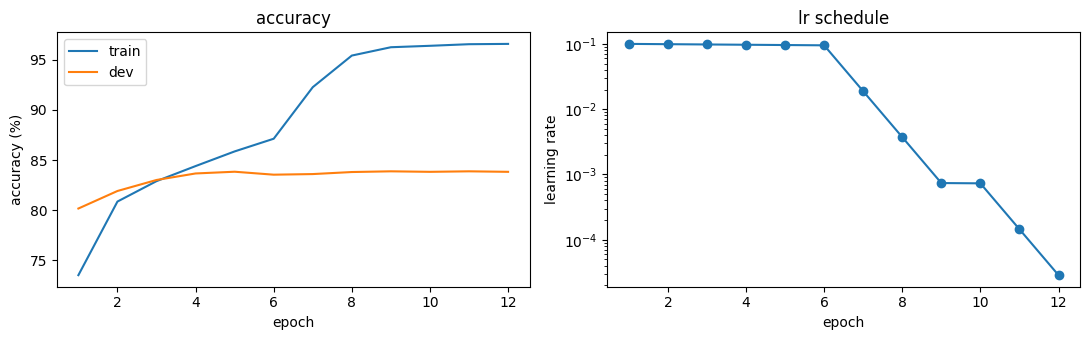

predicted,contradiction,entailment,neutral
gold,,,
contradiction,2790,143,304
entailment,96,2923,349
neutral,347,327,2545


In [11]:
if CFG['SKIP_MAIN']:
    print('skipped (SKIP_MAIN=True)')
else:
    # ============================================================
    # 4c. FINAL RESULTS + CURVES
    # ============================================================
    best = torch.load(BEST_CK, map_location=device, weights_only=False)
    model.load_state_dict(best['model'])
    dev_acc, test_acc = evaluate(model, dev_loader), evaluate(model, test_loader)
    extra_acc = {k: evaluate(model, ld) for k, ld in extra_loaders.items()}
    if CFG['TRAIN_DATA'] == 'SST':
        print(f'[{TAG}]  SST dev = {dev_acc:.2f}   SST test = {test_acc:.2f}')
        snli_dev = snli_test = None
    elif CFG['TRAIN_DATA'] == 'AllNLI':
        snli_dev, snli_test = extra_acc['snli_dev'], test_acc
        print(f'[{TAG}]  SNLI dev = {snli_dev:.2f}  SNLI test = {snli_test:.2f}  MNLI matched = {extra_acc["mnli_matched"]:.2f}  mismatched = {extra_acc["mnli_mismatched"]:.2f}')
    else:
        snli_dev, snli_test = dev_acc, test_acc
        print(f'[{TAG}]  SNLI dev = {dev_acc:.2f}   SNLI test = {test_acc:.2f}   (paper, BiLSTM-max 4096: dev 85.0 / test 84.5)')

    hist = pd.DataFrame(state['history'])
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(hist.epoch, hist.train_acc, label='train'); ax[0].plot(hist.epoch, hist.dev_acc, label='dev')
    ax[0].set_xlabel('epoch'); ax[0].set_ylabel('accuracy (%)'); ax[0].legend(); ax[0].set_title('accuracy')
    ax[1].semilogy(hist.epoch, hist.lr, marker='o'); ax[1].set_xlabel('epoch'); ax[1].set_ylabel('learning rate'); ax[1].set_title('lr schedule')
    plt.tight_layout(); plt.savefig(f'{OUT_DIR}/curves_{TAG}.png', dpi=150); plt.show()

    if CFG['TRAIN_DATA'] != 'SST':
        @torch.no_grad()
        def predict(model, loader):
            model.eval(); ps, ys = [], []
            for batch in loader:
                P, pl, H, hl, y = to_dev(batch)
                with torch.autocast('cuda', dtype=torch.float16, enabled=use_amp):
                    ps.append(model(P, pl, H, hl).argmax(1).cpu())
                ys.append(y.cpu())
            return torch.cat(ps).numpy(), torch.cat(ys).numpy()
        pr, gt = predict(model, test_loader)
        display(pd.crosstab(pd.Series(gt, name='gold').map(dict(enumerate(LABEL_NAMES))), pd.Series(pr, name='predicted').map(dict(enumerate(LABEL_NAMES)))))

    RES = save_results(TAG, tag=TAG, arch=CFG['ARCH'], enc_dim=CFG['ENC_DIM'], train_data=CFG['TRAIN_DATA'],
                       snli_dev=snli_dev, snli_test=snli_test, dev_acc=dev_acc, test_acc=test_acc, extra_acc=extra_acc,
                       epochs=len(state['history']), converged=bool(converged), history=state['history'],
                       cfg={k: CFG[k] for k in ['FC_STYLE', 'LR_RULE', 'DROPOUT', 'OPTIMIZER', 'USE_AMP', 'SEED', 'MAX_EPOCHS', 'TRAIN_SUBSET']})

## 5. Transfer learning with **SentEval** (paper Sec. 4–5, Table 4)
The encoder is **frozen**; a logistic regression is trained on its embeddings (SentEval: Adam, batch 64, L2 grid-searched on validation data). At transfer time the vocabulary is **all of GloVe** (the encoder was trained on a small vocabulary, but GloVe is fixed, so any GloVe word can be encoded).
Metrics: accuracy (MR, CR, SUBJ, MPQA, SST, TREC, SICK-E; 10-fold CV on MR/CR/SUBJ/MPQA), accuracy/F1 (MRPC), Pearson (SICK-R), Pearson/Spearman of cosine similarity (STS14, unsupervised).
Results are cached task by task, so a crashed run can simply be re-run.

In [12]:
# ============================================================
# 5a. TRANSFER HELPERS (batchers, SentEval runner, summary)
# ============================================================
def prepare(params, samples):
    return

def make_batcher(encoder):
    '''SentEval batcher for any SentenceEncoder (GloVe, all 2.2M words, as fixed embedding layer).'''
    encoder.eval()
    def batcher(params, batch):
        seqs = [torch.from_numpy(GLOVE[glove_rows(s)]) for s in batch]
        lengths = torch.tensor([len(s) for s in seqs])
        emb = pad_sequence(seqs, batch_first=True).to(device)
        with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16, enabled=(CFG['USE_AMP'] and device.type == 'cuda')):
            out = encoder(emb, lengths)
        return out.float().cpu().numpy()
    return batcher

def make_bow_batcher(lookup, dim=300, mode='mean'):
    '''bag-of-words baselines of Table 4. mode: "mean" or "pe" (positional encoding, Hill et al. 2016).'''
    def batcher(params, batch):
        out = np.zeros((len(batch), dim), dtype=np.float32)
        for i, sent in enumerate(batch):
            vs = []
            for w in sent:
                if isinstance(w, bytes): w = w.decode('utf-8', 'ignore')
                v = lookup(w)
                if v is not None: vs.append(v)
            if not vs: continue
            V = np.stack(vs)
            if mode == 'mean':
                out[i] = V.mean(0)
            else:                                              # l_jk = (1 - j/J) - (k/d)(1 - 2j/J);  sentence = sum_j l_j * w_j
                J, d = V.shape
                j = np.arange(1, J + 1, dtype=np.float32)[:, None]; k = np.arange(1, d + 1, dtype=np.float32)[None, :]
                out[i] = (((1 - j / J) - (k / d) * (1 - 2 * j / J)) * V).sum(0)
        return out
    return batcher

glove_lookup = lambda w: GLOVE[GLOVE_W2I[w]] if w in GLOVE_W2I else None

def concat_batchers(batchers):
    def batcher(params, batch):
        return np.concatenate([b(params, batch) for b in batchers], axis=1)
    return batcher

ACC_TASKS = ['MR', 'CR', 'SUBJ', 'MPQA', 'SST2', 'TREC', 'MRPC', 'SICKEntailment']     # tasks whose metric is accuracy
TRANSFER_TASKS = ['STS14', 'MR', 'CR', 'SUBJ', 'MPQA', 'SST2', 'TREC', 'MRPC', 'SICKRelatedness', 'SICKEntailment']   # STS14 first: fast, fails early

def summarise_transfer(r):
    row = {'MR': r['MR']['acc'], 'CR': r['CR']['acc'], 'SUBJ': r['SUBJ']['acc'], 'MPQA': r['MPQA']['acc'],
           'SST': r['SST2']['acc'], 'TREC': r['TREC']['acc'],
           'MRPC acc': r['MRPC']['acc'], 'MRPC F1': r['MRPC']['f1'],
           'SICK-R (Pearson)': r['SICKRelatedness']['pearson'], 'SICK-E': r['SICKEntailment']['acc'],
           'STS14 Pearson': r['STS14']['all']['pearson']['wmean'], 'STS14 Spearman': r['STS14']['all']['spearman']['wmean']}
    dev = np.array([r[t]['devacc'] for t in ACC_TASKS], dtype=float)
    nd  = np.array([r[t]['ndev']   for t in ACC_TASKS], dtype=float)
    return {k: float(v) for k, v in row.items()}, float((dev * nd).sum() / nd.sum()), float(dev.mean())   # row, micro, macro

SENT_CACHE = {}
def run_senteval(batcher, name, meta, kfold=None, tasks=None):
    '''runs SentEval for `batcher`, caches per task, saves results_<name>.json (transfer: row / micro / macro).'''
    import logging; logging.basicConfig(format='%(asctime)s : %(message)s', level=logging.WARNING)
    kfold = kfold or CFG['SENTEVAL_KFOLD']
    prev = find_results(name)
    if CFG['REUSE_RESULTS'] and prev and prev.get('transfer') and prev.get('transfer_kfold', kfold) == kfold:
        print(f'[{name}] transfer result found -> reused (set REUSE_RESULTS=False to recompute)')
        t = prev['transfer']; save_results(name, **meta); return t['row'], t['micro'], t['macro']
    params = {'task_path': TASK_PATH, 'usepytorch': True, 'kfold': kfold,
              'classifier': {'nhid': 0, 'optim': 'adam', 'batch_size': 64, 'tenacity': 5, 'epoch_size': 4}}
    se = senteval.engine.SE(params, batcher, prepare)
    cache = SENT_CACHE.setdefault(name, {})
    for t in (tasks or TRANSFER_TASKS):
        if t in cache: continue
        t1 = time.time(); cache[t] = se.eval(t)
        print(f'  [{name}] {t:16s} finished in {(time.time()-t1)/60:.1f} min')
        try:
            json.dump({k: {kk: vv for kk, vv in v.items() if kk != 'yhat'} for k, v in cache.items()},
                      open(f'{OUT_DIR}/senteval_raw_{name}.json', 'w'), default=str, indent=1)
        except Exception as e:
            print('raw dump skipped:', e)
    row, micro, macro = summarise_transfer(cache)
    save_results(name, transfer=dict(row=row, micro=micro, macro=macro), transfer_kfold=kfold, **meta)
    print(f'[{name}] micro {micro:.1f} | macro {macro:.1f}')
    return row, micro, macro

In [13]:
if CFG['SKIP_MAIN']:
    print('skipped (SKIP_MAIN=True)')
else:
    # ============================================================
    # 5b. RUN TRANSFER EVALUATION OF THE TRAINED MODEL   (~20-60 min per 1 GPU-hour of encoder size; ≈2.4 h for 4096-d with 10 folds)
    # ============================================================
    if CFG['RUN_TRANSFER']:
        row, micro, macro = run_senteval(make_batcher(model.encoder), TAG,
                                         meta=dict(tag=TAG, arch=CFG['ARCH'], enc_dim=CFG['ENC_DIM']))
        display(pd.DataFrame([row], index=[f'{TAG} (ours)']).round(3))
        print(f'Transfer dev averages -> micro {micro:.1f} | macro {macro:.1f}   (paper BiLSTM-max 4096: micro 85.2 | macro 83.7)')

  [BiLSTM-Max_4096] STS14            finished in 0.0 min
  [BiLSTM-Max_4096] MR               finished in 37.6 min
  [BiLSTM-Max_4096] CR               finished in 14.8 min
  [BiLSTM-Max_4096] SUBJ             finished in 38.3 min
  [BiLSTM-Max_4096] MPQA             finished in 36.4 min
  [BiLSTM-Max_4096] SST2             finished in 3.7 min
  [BiLSTM-Max_4096] TREC             finished in 3.0 min
  [BiLSTM-Max_4096] MRPC             finished in 1.6 min
  [BiLSTM-Max_4096] SICKRelatedness  finished in 0.4 min
  [BiLSTM-Max_4096] SICKEntailment   finished in 0.3 min
[BiLSTM-Max_4096] micro 85.1 | macro 84.0


,MR,CR,SUBJ,MPQA,SST,TREC,MRPC acc,MRPC F1,SICK-R (Pearson),SICK-E,STS14 Pearson,STS14 Spearman
BiLSTM-Max_4096 (ours),78.23,82.31,92.19,88.5,81.93,89.2,74.32,81.79,0.886,84.37,0.674,0.659


Transfer dev averages -> micro 85.1 | macro 84.0   (paper BiLSTM-max 4096: micro 85.2 | macro 83.7)


## 6. Table 5 — COCO image-caption retrieval (paper Sec. 4 & 5.2)
Sentence embeddings (from the frozen encoder) and **ResNet-101 image features** (2048-d, 113k training images, 5k validation, 5k test; Karpathy splits) are projected into a joint space by two learned linear maps $U,V$ (1000-d), trained with the pairwise ranking loss of the paper (margin α = 0.2, 30 contrastive terms). Test: average over five splits of 1k test images → Recall@{1,5,10} and median rank for **caption retrieval** (image → text) and **image retrieval** (text → image).
*Implementation note:* this is my own GPU implementation of the SentEval protocol (SentEval's version needs ≈ 30 GB RAM for 4096-d and breaks on modern numpy). Negatives are sampled uniformly from the training set.
The COCO features are downloaded from SentEval's public mirror (≈ 2 GB). Needs a trained model (`<TAG>_best.pt` in `outputs/` or in an attached input).

In [14]:
# ============================================================
# 6a. COCO RETRIEVAL: functions
# ============================================================
COCO_URL = 'https://dl.fbaipublicfiles.com/senteval/coco_r101_feat'

def load_trained_encoder(tag):
    '''rebuild the encoder of a finished run from <tag>_best.pt'''
    ck, res = find_ckpt(f'{tag}_best.pt'), find_results(tag)
    if ck is None or res is None:
        raise FileNotFoundError(f'need {tag}_best.pt and results_{tag}.json (attach the output of that run as a Kaggle input)')
    sd = torch.load(ck, map_location=device, weights_only=False)['model']
    enc = SentenceEncoder(res['arch'], 300, res['enc_dim']).to(device)
    enc.load_state_dict({k[len('encoder.'):]: v for k, v in sd.items() if k.startswith('encoder.')})
    return enc.eval()

def ensure_coco():
    d = f'{DS}/COCO'; os.makedirs(d, exist_ok=True)
    for split in ['train', 'valid', 'test']:
        p = f'{d}/{split}.pkl'
        if os.path.exists(p) and os.path.getsize(p) > 0: continue
        cands = [c for c in glob.glob(f'/kaggle/input/**/{split}.pkl', recursive=True) if 'coco' in c.lower()]
        if cands: shutil.copy(cands[0], p)
        else: download(f'{COCO_URL}/{split}.pkl', p)
    return d

def load_coco(d):
    out = {}
    for split in ['train', 'valid', 'test']:
        with open(f'{d}/{split}.pkl', 'rb') as f: cd = pickle.load(f, encoding='latin1')
        sents = []
        for k in range(len(cd['features'])):
            ids = cd['image_to_caption_ids'][k]
            assert len(ids) >= 5
            for cid in ids[:5]:
                s = cd['captions'][cid]['cleaned_caption']
                if isinstance(s, bytes): s = s.decode('utf-8', 'ignore')
                sents.append((s + ' .').split())
        out[split] = (sents, np.asarray(cd['features'], dtype=np.float32))     # 5 captions per image, in image order
        print(f'  COCO {split}: {len(cd["features"]):,} images, {len(sents):,} captions')
    return out

@torch.no_grad()
def encode_captions(sents, batcher, bs=512):
    order = np.argsort([len(s) for s in sents], kind='stable')
    out = None
    for i in range(0, len(order), bs):
        idx = order[i:i + bs]
        e = batcher(None, [sents[j] for j in idx])
        if out is None: out = torch.empty(len(sents), e.shape[1], dtype=torch.float16)
        out[torch.from_numpy(idx)] = torch.from_numpy(e).half()
    return out

class ProjNet(nn.Module):
    def __init__(self, sd, imd, pd=1000):
        super().__init__(); self.sp = nn.Linear(sd, pd); self.ip = nn.Linear(imd, pd)
    def s(self, x): return F.normalize(self.sp(x.float()), dim=-1)
    def i(self, x): return F.normalize(self.ip(x.float()), dim=-1)

def _metrics(ranks):
    return [100.0 * (ranks < 1).mean(), 100.0 * (ranks < 5).mean(), 100.0 * (ranks < 10).mean(), float(np.floor(np.median(ranks)) + 1)]

@torch.no_grad()
def retrieval_scores(net, caps, imgs):
    '''average over folds of 1k images (5k captions): returns (i2t = caption retrieval, t2i = image retrieval), each [R@1, R@5, R@10, Med r]'''
    net.eval(); dev_ = caps.device; folds = []
    ar1000 = torch.arange(1000, device=dev_)
    cols = (5 * ar1000)[:, None] + torch.arange(5, device=dev_)[None, :]
    for f in range(0, imgs.shape[0] // 1000 * 1000, 1000):
        I, C = net.i(imgs[f:f + 1000]), net.s(caps[5 * f:5 * (f + 1000)])
        sims = I @ C.t()                                                         # (1000 images, 5000 captions)
        order = sims.argsort(dim=1, descending=True)
        pos = torch.empty_like(order); pos.scatter_(1, order, torch.arange(5000, device=dev_)[None, :].expand(1000, -1).contiguous())
        r_i2t = pos.gather(1, cols).min(1).values.cpu().numpy()                  # best-ranked of the 5 true captions
        order2 = sims.t().argsort(dim=1, descending=True)                        # (5000, 1000)
        pos2 = torch.empty_like(order2); pos2.scatter_(1, order2, ar1000[None, :].expand(5000, -1).contiguous())
        true = (torch.arange(5000, device=dev_) // 5)[:, None]
        r_t2i = pos2.gather(1, true).squeeze(1).cpu().numpy()
        folds.append((_metrics(r_i2t), _metrics(r_t2i)))
    return np.mean([f[0] for f in folds], 0).tolist(), np.mean([f[1] for f in folds], 0).tolist()

def train_coco(caps, imgs, margin=0.2, ncontrast=30, bs=128, max_epochs=20, patience=3, seed=1111):
    torch.manual_seed(seed)
    N, SD = caps['train'].shape; ID = imgs['train'].shape[1]
    net = ProjNet(SD, ID).to(device); opt = torch.optim.Adam(net.parameters())
    best, best_sd, bad = -1, None, 0
    for ep in range(1, max_epochs + 1):
        net.train(); perm = torch.randperm(N, device=device); tot = 0.0; t0 = time.time()
        for i in range(0, N, bs):
            idx = perm[i:i + bs]; B = idx.numel()
            x, y = net.s(caps['train'][idx]), net.i(imgs['train'][idx // 5])             # (B,P)
            nc = torch.randint(0, N, (B, ncontrast), device=device); ni = torch.randint(0, N, (B, ncontrast), device=device)
            xk = net.s(caps['train'][nc].reshape(-1, SD)).view(B, ncontrast, -1)         # negative captions
            yk = net.i(imgs['train'][ni // 5].reshape(-1, ID)).view(B, ncontrast, -1)    # negative images
            pos = (x * y).sum(-1, keepdim=True)
            l1 = F.relu(margin - pos + torch.einsum('bkp,bp->bk', xk, y))                # image anchor vs wrong captions
            l2 = F.relu(margin - pos + torch.einsum('bkp,bp->bk', yk, x))                # caption anchor vs wrong images
            loss = (l1.sum(1) + l2.sum(1)).mean()
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); tot += loss.item()
        i2t, t2i = retrieval_scores(net, caps['valid'], imgs['valid'])
        score = sum(i2t[:3]) + sum(t2i[:3])
        print(f'  COCO epoch {ep:2d} | loss {tot / (N / bs):.3f} | dev recall-sum {score:.1f} | {time.time() - t0:.0f}s')
        if score > best: best, bad, best_sd = score, 0, {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    net.load_state_dict(best_sd)
    return net

def run_coco(tag):
    prev = find_results(tag)
    if CFG['REUSE_RESULTS'] and prev and prev.get('coco'):
        print(f'[{tag}] COCO result found -> reused'); return prev['coco']
    global COCO_DATA
    if 'COCO_DATA' not in globals(): COCO_DATA = load_coco(ensure_coco())
    batcher = make_batcher(load_trained_encoder(tag))
    caps = {s: encode_captions(COCO_DATA[s][0], batcher).to(device) for s in COCO_DATA}
    imgs = {s: torch.from_numpy(COCO_DATA[s][1]).half().to(device) for s in COCO_DATA}
    net = train_coco(caps, imgs)
    i2t, t2i = retrieval_scores(net, caps['test'], imgs['test'])
    print(f'[{tag}] caption retrieval R@1/5/10, Med r: {np.round(i2t, 1)} | image retrieval: {np.round(t2i, 1)}')
    res = dict(i2t=i2t, t2i=t2i); save_results(tag, coco=res)
    del caps, imgs, net; torch.cuda.empty_cache()
    return res

In [15]:
# ============================================================
# 6b. RUN COCO RETRIEVAL (RUN_COCO=True)
# ============================================================
if CFG['RUN_COCO']:
    for _tag in (CFG['COCO_TAGS'] or [TAG]):
        run_coco(_tag)
else:
    print('RUN_COCO=False -> skipped')

RUN_COCO=False -> skipped


## 7. Table 4 baselines: untrained BiLSTM-Max and bag-of-words models (`RUN_BASELINES=True`)
* **BiLSTM-Max (untrained):** same 4096-d architecture with random weights — shows how much of the performance comes from NLI training.
* **GloVe BOW**, **GloVe positional encoding** (Hill et al., 2016): average / position-weighted sum of GloVe vectors.
* optional (`RUN_BOW_EXTRA=True`): **fastText BOW** and **word2vec BOW** (the paper's rows; they use other pre-trained vectors that need extra downloads).
Use `SKIP_MAIN=True` for this run so no model is trained.

In [16]:
# ============================================================
# 7. BASELINES
# ============================================================
if CFG['RUN_BASELINES']:
    torch.manual_seed(CFG['SEED'])
    enc_untrained = SentenceEncoder('BiLSTM-Max', 300, 4096).to(device)
    run_senteval(make_batcher(enc_untrained), 'BiLSTM-Max-untrained_4096', meta=dict(tag='BiLSTM-Max-untrained_4096', arch='BiLSTM-Max (untrained)', enc_dim=4096))
    del enc_untrained
    run_senteval(make_bow_batcher(glove_lookup, 300, 'mean'), 'GloVe-BOW', meta=dict(tag='GloVe-BOW', arch='GloVe BOW', enc_dim=300))
    run_senteval(make_bow_batcher(glove_lookup, 300, 'pe'), 'GloVe-PositionalEncoding', meta=dict(tag='GloVe-PositionalEncoding', arch='GloVe Positional Encoding', enc_dim=300))
    if CFG['RUN_BOW_EXTRA']:
        try:    # fastText (wiki-news-300d-1M)
            vec = glob.glob('/kaggle/input/**/wiki-news-300d-1M.vec', recursive=True)
            if not vec:
                zp = download('https://dl.fbaipublicfiles.com/fasttext/vectors-english/wiki-news-300d-1M.vec.zip', f'{DATA_DIR}/ft.zip')
                with zipfile.ZipFile(zp) as z: z.extract('wiki-news-300d-1M.vec', DATA_DIR)
                vec = [f'{DATA_DIR}/wiki-news-300d-1M.vec']
            ft_w2i, ft_mat = load_text_vectors(vec[0], skip_header=True)
            run_senteval(make_bow_batcher(lambda w: ft_mat[ft_w2i[w]] if w in ft_w2i else None), 'FastText-BOW',
                         meta=dict(tag='FastText-BOW', arch='fastText BOW', enc_dim=300))
            del ft_w2i, ft_mat
        except Exception as e:
            print('fastText BOW skipped:', e)
        try:    # word2vec (GoogleNews) - attach a Kaggle dataset that contains GoogleNews-vectors-negative300.bin
            p = (glob.glob('/kaggle/input/**/GoogleNews-vectors-negative300.bin*', recursive=True) or [None])[0]
            if p is None: raise FileNotFoundError('GoogleNews-vectors-negative300.bin not found in /kaggle/input')
            from gensim.models import KeyedVectors
            kv = KeyedVectors.load_word2vec_format(p, binary=True)
            run_senteval(make_bow_batcher(lambda w: kv[w] if w in kv else None), 'Word2vec-BOW',
                         meta=dict(tag='Word2vec-BOW', arch='word2vec BOW', enc_dim=300))
            del kv
        except Exception as e:
            print('word2vec BOW skipped:', e)
else:
    print('RUN_BASELINES=False -> skipped')

RUN_BASELINES=False -> skipped


## 8. Improvement experiment 4 — concatenated embeddings (`RUN_ENSEMBLE=True`)
No retraining: embeddings of several already-trained encoders (and/or the GloVe-BOW vector) are **concatenated** and fed to the same SentEval logistic regression. Ingredients: `ENSEMBLE_ITEMS`; trained tags need their `*_best.pt` + `results_*.json` in `outputs/` or an attached input. Features are larger (e.g. 4096+4096+300), so use `ENSEMBLE_KFOLD=5`.

In [17]:
# ============================================================
# 8. ENSEMBLE OF EMBEDDINGS (improvement)
# ============================================================
if CFG['RUN_ENSEMBLE']:
    parts, names, dim = [], [], 0
    for item in CFG['ENSEMBLE_ITEMS']:
        try:
            if item == 'GloVe-BOW':
                parts.append(make_bow_batcher(glove_lookup, 300, 'mean')); dim += 300
            else:
                enc = load_trained_encoder(item); parts.append(make_batcher(enc)); dim += enc.enc_dim
            names.append(item)
        except Exception as e:
            print(f'  ensemble item {item} skipped: {e}')
    if len(parts) >= 2:
        ens_name = 'ENS__' + '__'.join(names)
        run_senteval(concat_batchers(parts), ens_name, meta=dict(tag=ens_name, arch='ensemble', enc_dim=dim), kfold=CFG['ENSEMBLE_KFOLD'])
    else:
        print('need at least 2 usable items')
else:
    print('RUN_ENSEMBLE=False -> skipped')

RUN_ENSEMBLE=False -> skipped


## 9. Max-pooling analysis (paper Appendix, Figs. 6–9) and a demo
Max-pooling lets each of the 4096 dimensions pick **one time step**. Counting how many dimensions pick each word shows what the encoder considers important: the paper reports that the **untrained** BiLSTM selects fairly evenly (with a bias to the first and last states), while the **trained** one focuses on words that carry the meaning of the sentence. Only for `ARCH='BiLSTM-Max'`.

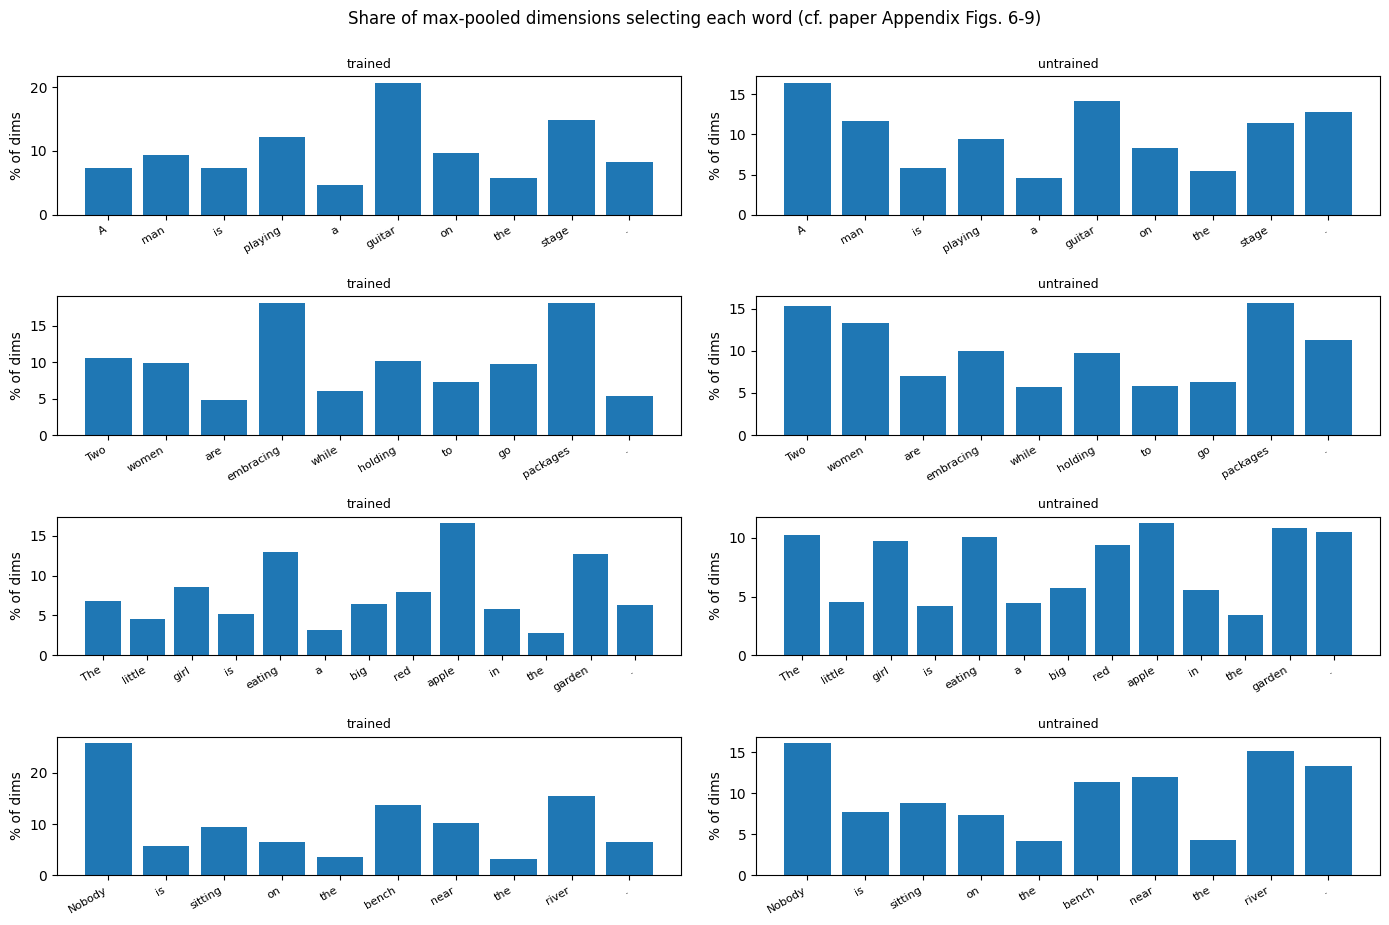

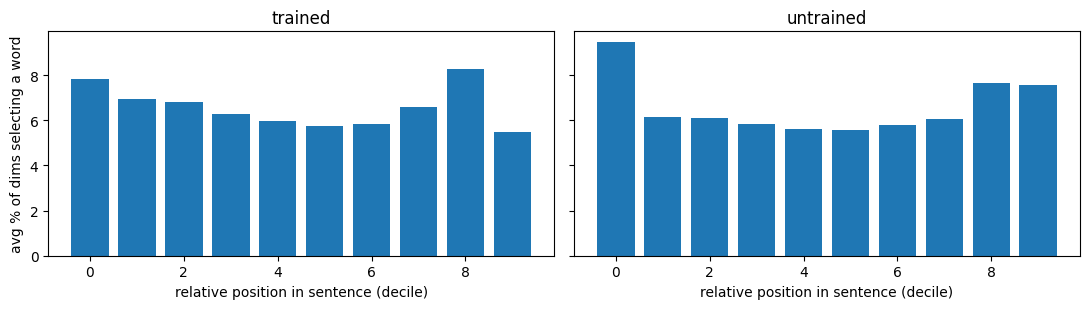

In [18]:
if CFG['SKIP_MAIN']:
    print('skipped (SKIP_MAIN=True)')
else:
    # ============================================================
    # 9a. MAX-POOL SELECTION: trained vs untrained
    # ============================================================
    @torch.no_grad()
    def maxpool_selection(sentence, enc):
        toks = [w for w in tokenize(sentence) if w in GLOVE_W2I]
        emb = torch.from_numpy(GLOVE[[GLOVE_W2I[w] for w in toks]])[None].to(device)
        out = enc.states(emb, torch.tensor([len(toks)]))[0].float()                 # (T, D)
        counts = torch.bincount(out.argmax(0), minlength=len(toks)).cpu().numpy()   # dimensions "voting" for each word
        return toks, 100 * counts / counts.sum()

    if CFG['ARCH'] == 'BiLSTM-Max':
        model.eval()
        torch.manual_seed(CFG['SEED'])
        untrained_enc = SentenceEncoder('BiLSTM-Max', 300, CFG['ENC_DIM']).to(device).eval()      # same architecture, random weights
        sents = ['A man is playing a guitar on the stage .',
                 'Two women are embracing while holding to go packages .',
                 'The little girl is eating a big red apple in the garden .',
                 'Nobody is sitting on the bench near the river .']
        fig, axs = plt.subplots(len(sents), 2, figsize=(14, 2.3 * len(sents)))
        for row, s in zip(axs, sents):
            for a, enc, name in zip(row, (model.encoder, untrained_enc), ('trained', 'untrained')):
                toks, pct = maxpool_selection(s, enc)
                a.bar(range(len(toks)), pct); a.set_xticks(range(len(toks))); a.set_xticklabels(toks, rotation=30, ha='right', fontsize=8)
                a.set_ylabel('% of dims'); a.set_title(name, fontsize=9)
        plt.suptitle('Share of max-pooled dimensions selecting each word (cf. paper Appendix Figs. 6-9)', y=1.0)
        plt.tight_layout(); plt.savefig(f'{OUT_DIR}/maxpool_selection.png', dpi=150); plt.show()

        fig, axs = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
        for a, enc, name in zip(axs, (model.encoder, untrained_enc), ('trained', 'untrained')):
            pos_share = np.zeros(10); cnt = np.zeros(10)
            for r_ in SPLITS['test'][:1500]:
                toks, pct = maxpool_selection(r_[0], enc)
                rel = np.minimum((np.arange(len(toks)) * 10 / max(len(toks), 1)).astype(int), 9)
                for q, p_ in zip(rel, pct): pos_share[q] += p_; cnt[q] += 1
            a.bar(range(10), pos_share / np.maximum(cnt, 1)); a.set_title(name); a.set_xlabel('relative position in sentence (decile)')
        axs[0].set_ylabel('avg % of dims selecting a word')
        plt.tight_layout(); plt.savefig(f'{OUT_DIR}/maxpool_position.png', dpi=150); plt.show()
    else:
        print('Skipped: this analysis is for ARCH = BiLSTM-Max.')

In [19]:
if CFG['SKIP_MAIN']:
    print('skipped (SKIP_MAIN=True)')
else:
    # ============================================================
    # 9b. DEMO: sentence similarity with the trained encoder
    # ============================================================
    _bt = make_batcher(model.encoder)
    sents = ['A man is playing a guitar.', 'Someone is strumming a guitar.', 'A woman is cooking pasta in the kitchen.',
             'The chef prepares noodles.', 'Stock markets fell sharply on Monday.']
    E = _bt(None, [tokenize(s) for s in sents]); E = E / np.linalg.norm(E, axis=1, keepdims=True)
    display(pd.DataFrame(E @ E.T, index=[s[:32] for s in sents], columns=range(len(sents))).round(2).style.background_gradient(cmap='Blues'))

,0,1,2,3,4
A man is playing a guitar.,1.000000,0.760000,0.120000,0.090000,0.020000
Someone is strumming a guitar.,0.760000,1.000000,0.160000,0.110000,0.060000
A woman is cooking pasta in the,0.120000,0.160000,1.000000,0.600000,0.180000
The chef prepares noodles.,0.090000,0.110000,0.600000,1.000000,0.180000
Stock markets fell sharply on Mo,0.020000,0.060000,0.180000,0.180000,1.000000


## 10. Results: the paper's tables, side by side with ours
`runs` below = every `results_*.json` found in `outputs/` and in attached Kaggle inputs. Rows marked **[ours]** are produced by this notebook; all other rows are **copied from the paper** (they come from other works or other models and are not re-run).

In [20]:
# ============================================================
# 10a. COLLECT ALL RUNS
# ============================================================
files = sorted(set(glob.glob(f'{OUT_DIR}/results_*.json') + glob.glob('/kaggle/input/**/results_*.json', recursive=True)))
runs = {}
for f in files:
    try:
        r = json.load(open(f)); runs[r.get('tag', os.path.basename(f)[8:-5])] = r      # later files override earlier ones
    except Exception as e:
        print('could not read', f, e)
print(f'{len(runs)} runs found:', list(runs))

1 runs found: ['BiLSTM-Max_4096']


,dim,NLI dev (ours),NLI dev (paper),NLI test (ours),NLI test (paper),micro (ours),micro (paper),macro (ours),macro (paper),epochs
Model,,,,,,,,,,
LSTM,2048,NaN,81.9,NaN,80.7,NaN,79.5,NaN,78.6,NaN
GRU,4096,NaN,82.4,NaN,81.8,NaN,81.7,NaN,80.9,NaN
BiGRU-last,4096,NaN,81.3,NaN,80.9,NaN,82.9,NaN,81.7,NaN
BiLSTM-Mean,4096,NaN,79.0,NaN,78.2,NaN,83.1,NaN,81.7,NaN
Inner-attention,4096,NaN,82.3,NaN,82.5,NaN,82.1,NaN,81.0,NaN
HConvNet,4096,NaN,83.7,NaN,83.4,NaN,82.0,NaN,80.9,NaN
BiLSTM-Max,4096,83.9,85.0,84.1,84.5,85.1,85.2,84.0,83.7,12.0


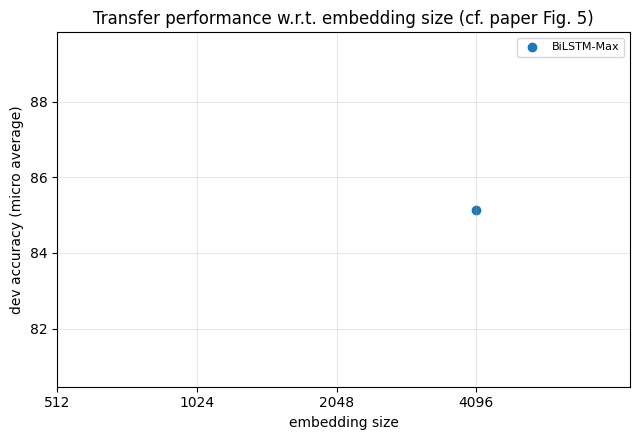

In [21]:
# ============================================================
# 10b. TABLE 3 (7 encoders)  +  FIGURE 5 (embedding size)
# ============================================================
PAPER_T3 = {'LSTM': (2048, 81.9, 80.7, 79.5, 78.6), 'GRU': (4096, 82.4, 81.8, 81.7, 80.9),
            'BiGRU-last': (4096, 81.3, 80.9, 82.9, 81.7), 'BiLSTM-Mean': (4096, 79.0, 78.2, 83.1, 81.7),
            'Inner-attention': (4096, 82.3, 82.5, 82.1, 81.0), 'HConvNet': (4096, 83.7, 83.4, 82.0, 80.9),
            'BiLSTM-Max': (4096, 85.0, 84.5, 85.2, 83.7)}          # arch -> (dim, NLI dev, NLI test, micro, macro)  [paper Table 3]
rows = []
for arch, (dim, pd_dev, pd_test, pd_mi, pd_ma) in PAPER_T3.items():
    r = runs.get(f'{arch}_{dim}'); t = (r or {}).get('transfer') or {}
    rows.append({'Model': arch, 'dim': dim, 'NLI dev (ours)': r and r.get('snli_dev'), 'NLI dev (paper)': pd_dev,
                 'NLI test (ours)': r and r.get('snli_test'), 'NLI test (paper)': pd_test,
                 'micro (ours)': t.get('micro'), 'micro (paper)': pd_mi, 'macro (ours)': t.get('macro'), 'macro (paper)': pd_ma,
                 'epochs': r and r.get('epochs')})
T3 = pd.DataFrame(rows).set_index('Model')
display(T3.round(1)); T3.to_csv(f'{OUT_DIR}/table3_comparison.csv')

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for arch in PAPER_T3:
    pts = sorted((r['enc_dim'], r['transfer']['micro']) for r in runs.values()
                 if r.get('arch') == arch and r.get('transfer') and r.get('train_data', 'SNLI') == 'SNLI'
                 and r.get('cfg', {}).get('FC_STYLE', 'linear3') == 'linear3' and r.get('cfg', {}).get('OPTIMIZER', 'sgd') == 'sgd'
                 and not r.get('cfg', {}).get('DROPOUT'))
    if len(pts) >= 2: ax.plot(*zip(*pts), marker='o', label=arch)
    elif len(pts) == 1: ax.scatter(*pts[0], label=arch)
ax.set_xscale('log', base=2); ax.set_xticks([512, 1024, 2048, 4096]); ax.set_xticklabels([512, 1024, 2048, 4096])
ax.set_xlabel('embedding size'); ax.set_ylabel('dev accuracy (micro average)'); ax.grid(alpha=.3); ax.legend(fontsize=8)
ax.set_title('Transfer performance w.r.t. embedding size (cf. paper Fig. 5)')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/figure5_replication.png', dpi=150); plt.show()

In [22]:
# ============================================================
# 10c. TABLE 4 (transfer test results): paper rows + [ours]
# ============================================================
COLS4 = ['MR', 'CR', 'SUBJ', 'MPQA', 'SST', 'TREC', 'MRPC', 'SICK-R', 'SICK-E', 'STS14']
REF4 = [  # (group, model, MR, CR, SUBJ, MPQA, SST, TREC, MRPC, SICK-R, SICK-E, STS14)      -- copied from the paper's Table 4
 ('Unsup. (unordered)', 'Unigram-TFIDF', '73.7','79.2','90.3','82.4','-','85.0','73.6/81.7','-','-','.58/.57'),
 ('Unsup. (unordered)', 'ParagraphVec (DBOW)', '60.2','66.9','76.3','70.7','-','59.4','72.9/81.1','-','-','.42/.43'),
 ('Unsup. (unordered)', 'SDAE', '74.6','78.0','90.8','86.9','-','78.4','73.7/80.7','-','-','.37/.38'),
 ('Unsup. (unordered)', 'SIF (GloVe + WR)', '-','-','-','-','82.2','-','-','-','84.6','.69/-'),
 ('Unsup. (unordered)', 'word2vec BOW†', '77.7','79.8','90.9','88.3','79.7','83.6','72.5/81.4','0.803','78.7','.65/.64'),
 ('Unsup. (unordered)', 'fastText BOW†', '76.5','78.9','91.6','87.4','78.8','81.8','72.4/81.2','0.800','77.9','.63/.62'),
 ('Unsup. (unordered)', 'GloVe BOW†', '78.7','78.5','91.6','87.6','79.8','83.6','72.1/80.9','0.800','78.6','.54/.56'),
 ('Unsup. (unordered)', 'GloVe Positional Encoding†', '78.3','77.4','91.1','87.1','80.6','83.3','72.5/81.2','0.799','77.9','.51/.54'),
 ('Unsup. (unordered)', 'BiLSTM-Max (untrained)†', '77.5','81.3','89.6','88.7','80.7','85.8','73.2/81.6','0.860','83.4','.39/.48'),
 ('Unsup. (ordered)', 'FastSent', '70.8','78.4','88.7','80.6','-','76.8','72.2/80.3','-','-','.63/.64'),
 ('Unsup. (ordered)', 'FastSent+AE', '71.8','76.7','88.8','81.5','-','80.4','71.2/79.1','-','-','.62/.62'),
 ('Unsup. (ordered)', 'SkipThought', '76.5','80.1','93.6','87.1','82.0','92.2','73.0/82.0','0.858','82.3','.29/.35'),
 ('Unsup. (ordered)', 'SkipThought-LN', '79.4','83.1','93.7','89.3','82.9','88.4','-','0.858','79.5','.44/.45'),
 ('Supervised', 'CaptionRep (bow)', '61.9','69.3','77.4','70.8','-','72.2','73.6/81.9','-','-','.46/.42'),
 ('Supervised', 'DictRep (bow)', '76.7','78.7','90.7','87.2','-','81.0','68.4/76.8','-','-','.67/.70'),
 ('Supervised', 'NMT En-to-Fr', '64.7','70.1','84.9','81.5','-','82.8','69.1/77.1','-','-','.43/.42'),
 ('Supervised', 'Paragram-phrase', '-','-','-','-','79.7','-','-','0.849','83.1','.71/-'),
 ('Supervised', 'BiLSTM-Max (on SST)†', '(*)','83.7','90.2','89.5','(*)','86.0','72.7/80.9','0.863','83.1','.55/.54'),
 ('Supervised', 'BiLSTM-Max (on SNLI)†', '79.9','84.6','92.1','89.8','83.3','88.7','75.1/82.3','0.885','86.3','.68/.65'),
 ('Supervised', 'BiLSTM-Max (on AllNLI)†', '81.1','86.3','92.4','90.2','84.6','88.2','76.2/83.1','0.884','86.3','.70/.67'),
 ('No transfer', 'Naive Bayes - SVM', '79.4','81.8','93.2','86.3','83.1','-','-','-','-','-'),
 ('No transfer', 'AdaSent', '83.1','86.3','95.5','93.3','-','92.4','-','-','-','-'),
 ('No transfer', 'TF-KLD', '-','-','-','-','-','-','80.4/85.9','-','-','-'),
 ('No transfer', 'Illinois-LH', '-','-','-','-','-','-','-','-','84.5','-'),
 ('No transfer', 'Dependency Tree-LSTM', '-','-','-','-','-','-','-','0.868','-','-'),
]
NAMES4 = {'BiLSTM-Max_4096': 'BiLSTM-Max (on SNLI) [ours]', 'BiLSTM-Max_4096_AllNLI': 'BiLSTM-Max (on AllNLI) [ours]',
          'BiLSTM-Max_4096_SST': 'BiLSTM-Max (on SST) [ours]', 'BiLSTM-Max-untrained_4096': 'BiLSTM-Max (untrained) [ours]',
          'GloVe-BOW': 'GloVe BOW [ours]', 'GloVe-PositionalEncoding': 'GloVe Positional Encoding [ours]',
          'FastText-BOW': 'fastText BOW [ours]', 'Word2vec-BOW': 'word2vec BOW [ours]'}
def fmt4(r, star=False):
    f1 = lambda x: f'{x:.1f}'
    v = [f1(r['MR']), f1(r['CR']), f1(r['SUBJ']), f1(r['MPQA']), f1(r['SST']), f1(r['TREC']), f"{r['MRPC acc']:.1f}/{r['MRPC F1']:.1f}",
         f"{r['SICK-R (Pearson)']:.3f}", f1(r['SICK-E']), f"{r['STS14 Pearson']:.2f}/{r['STS14 Spearman']:.2f}".replace('0.', '.')]
    if star: v[0] = v[4] = '(*)'
    return v
rows4 = [(g, n) + tuple(v) for g, n, *v in REF4]
ours = sorted([t for t, r in runs.items() if r.get('transfer')], key=lambda t: (t not in NAMES4, t))
for t in ours:
    rows4.append(('OURS', NAMES4.get(t, f'{t} [ours]'), *fmt4(runs[t]['transfer']['row'], star=t.endswith('_SST'))))
T4 = pd.DataFrame(rows4, columns=['group', 'Model'] + COLS4).set_index(['group', 'Model'])
pd.set_option('display.max_rows', 200, 'display.width', 250)
display(T4); T4.to_csv(f'{OUT_DIR}/table4_full.csv')

MR    CR  SUBJ  MPQA   SST  TREC       MRPC SICK-R SICK-E    STS14
group              Model                                                                                            
Unsup. (unordered) Unigram-TFIDF                73.7  79.2  90.3  82.4     -  85.0  73.6/81.7      -      -  .58/.57
                   ParagraphVec (DBOW)          60.2  66.9  76.3  70.7     -  59.4  72.9/81.1      -      -  .42/.43
                   SDAE                         74.6  78.0  90.8  86.9     -  78.4  73.7/80.7      -      -  .37/.38
                   SIF (GloVe + WR)                -     -     -     -  82.2     -          -      -   84.6    .69/-
                   word2vec BOW†                77.7  79.8  90.9  88.3  79.7  83.6  72.5/81.4  0.803   78.7  .65/.64
                   fastText BOW†                76.5  78.9  91.6  87.4  78.8  81.8  72.4/81.2  0.800   77.9  .63/.62
                   GloVe BOW†                   78.7  78.5  91.6  87.6  79.8  83.6  72.1/80.9  0.800   78.6  .54/.56
                   GloVe Positional Encoding†   78.3  77.4  91.1  87.1  80.6  83.3  72.5/81.2  0.799   77.9  .51/.54
                   BiLSTM-Max (untrained)†      77.5  81.3  89.6  88.7  80.7  85.8  73.2/81.6  0.860   83.4  .39/.48
Unsup. (ordered)   FastSent                     70.8  78.4  88.7  80.6     -  76.8  72.2/80.3      -      -  .63/.64
                   FastSent+AE                  71.8  76.7  88.8  81.5     -  80.4  71.2/79.1      -      -  .62/.62
                   SkipThought                  76.5  80.1  93.6  87.1  82.0  92.2  73.0/82.0  0.858   82.3  .29/.35
                   SkipThought-LN               79.4  83.1  93.7  89.3  82.9  88.4          -  0.858   79.5  .44/.45
Supervised         CaptionRep (bow)             61.9  69.3  77.4  70.8     -  72.2  73.6/81.9      -      -  .46/.42
                   DictRep (bow)                76.7  78.7  90.7  87.2     -  81.0  68.4/76.8      -      -  .67/.70
                   NMT En-to-Fr                 64.7  70.1  84.9  81.5     -  82.8  69.1/77.1      -      -  .43/.42
                   Paragram-phrase                 -     -     -     -  79.7     -          -  0.849   83.1    .71/-
                   BiLSTM-Max (on SST)†          (*)  83.7  90.2  89.5   (*)  86.0  72.7/80.9  0.863   83.1  .55/.54
                   BiLSTM-Max (on SNLI)†        79.9  84.6  92.1  89.8  83.3  88.7  75.1/82.3  0.885   86.3  .68/.65
                   BiLSTM-Max (on AllNLI)†      81.1  86.3  92.4  90.2  84.6  88.2  76.2/83.1  0.884   86.3  .70/.67
No transfer        Naive Bayes - SVM            79.4  81.8  93.2  86.3  83.1     -          -      -      -        -
                   AdaSent                      83.1  86.3  95.5  93.3     -  92.4          -      -      -        -
                   TF-KLD                          -     -     -     -     -     -  80.4/85.9      -      -        -
                   Illinois-LH                     -     -     -     -     -     -          -      -   84.5        -
                   Dependency Tree-LSTM            -     -     -     -     -     -          -  0.868      -        -
OURS               BiLSTM-Max (on SNLI) [ours]  78.2  82.3  92.2  88.5  81.9  89.2  74.3/81.8  0.886   84.4  .67/.66

In [23]:
# ============================================================
# 10d. TABLE 5 (COCO retrieval): paper rows + [ours]
# ============================================================
REF5 = [  # model, caption retrieval R@1, R@5, R@10, Med r | image retrieval R@1, R@5, R@10, Med r   -- copied from the paper's Table 5
 ('m-CNN (Ma et al., 2015)', '38.3','-','81.0','2','27.4','-','79.5','3'),
 ('m-CNN_ENS (Ma et al., 2015)', '42.8','-','84.1','2','32.6','-','82.8','3'),
 ('Order-embeddings (Vendrov et al., 2016)', '46.7','-','88.9','2','37.9','-','85.9','2'),
 ('SkipThought + VGG19 (82k)', '33.8','67.7','82.1','3','25.9','60.0','74.6','4'),
 ('SkipThought + ResNet101 (113k)', '37.9','72.2','84.3','2','30.6','66.2','81.0','3'),
 ('BiLSTM-Max (on SNLI) + ResNet101 (113k)', '42.4','76.1','87.0','2','33.2','69.7','83.6','3'),
 ('BiLSTM-Max (on AllNLI) + ResNet101 (113k)', '42.6','75.3','87.3','2','33.9','69.7','83.8','3')]
rows5 = [list(r) for r in REF5]
for t, r in runs.items():
    if r.get('coco'):
        a, b = r['coco']['i2t'], r['coco']['t2i']
        rows5.append([f'{NAMES4.get(t, t)} + ResNet101 (113k)'] + [f'{x:.1f}' for x in a[:3]] + [f'{a[3]:.0f}'] + [f'{x:.1f}' for x in b[:3]] + [f'{b[3]:.0f}'])
cols5 = pd.MultiIndex.from_tuples([('', 'Model')] + [('Caption retrieval', c) for c in ['R@1', 'R@5', 'R@10', 'Med r']] + [('Image retrieval', c) for c in ['R@1', 'R@5', 'R@10', 'Med r']])
T5 = pd.DataFrame(rows5, columns=cols5).set_index(('', 'Model'))
display(T5); T5.to_csv(f'{OUT_DIR}/table5_full.csv')

Caption retrieval                   Image retrieval                  
                                                        R@1   R@5  R@10 Med r             R@1   R@5  R@10 Med r
(, Model)                                                                                                      
m-CNN (Ma et al., 2015)                                38.3     -  81.0     2            27.4     -  79.5     3
m-CNN_ENS (Ma et al., 2015)                            42.8     -  84.1     2            32.6     -  82.8     3
Order-embeddings (Vendrov et al., 2016)                46.7     -  88.9     2            37.9     -  85.9     2
SkipThought + VGG19 (82k)                              33.8  67.7  82.1     3            25.9  60.0  74.6     4
SkipThought + ResNet101 (113k)                         37.9  72.2  84.3     2            30.6  66.2  81.0     3
BiLSTM-Max (on SNLI) + ResNet101 (113k)                42.4  76.1  87.0     2            33.2  69.7  83.6     3
BiLSTM-Max (on AllNLI) + ResNet101 (113k)              42.6  75.3  87.3     2            33.9  69.7  83.8     3

In [24]:
# ============================================================
# 10e. IMPROVEMENT EXPERIMENTS + Adam-vs-SGD: all BiLSTM-Max runs vs the paper
# ============================================================
paper_row = {'tag': 'PAPER (SNLI, BiLSTM-Max)', 'SNLI dev': 85.0, 'SNLI test': 84.5, 'micro': 85.2, 'macro': 83.7, 'epochs': 10,
             'MR': 79.9, 'CR': 84.6, 'SUBJ': 92.1, 'MPQA': 89.8, 'SST': 83.3, 'TREC': 88.7, 'SICK-E': 86.3}
tab = [paper_row]
for t, r in sorted(runs.items()):
    if r.get('arch') == 'BiLSTM-Max' and r.get('transfer'):
        row = r['transfer']['row']
        tab.append({'tag': t, 'SNLI dev': r.get('snli_dev'), 'SNLI test': r.get('snli_test'), 'micro': r['transfer']['micro'], 'macro': r['transfer']['macro'],
                    'epochs': r.get('epochs'), **{k: row[k] for k in ['MR', 'CR', 'SUBJ', 'MPQA', 'SST', 'TREC', 'SICK-E']}})
IMP = pd.DataFrame(tab).set_index('tag')
display(IMP.round(1)); IMP.to_csv(f'{OUT_DIR}/improvement_summary.csv')
if 'BiLSTM-Max_4096_adam' in runs and 'BiLSTM-Max_4096' in runs:
    a, s = runs['BiLSTM-Max_4096_adam'], runs['BiLSTM-Max_4096']
    print('Sec. 5.1 check (paper: Adam converges in ~5 epochs instead of 10, but transfers worse):')
    print(f"  SGD : {s['epochs']} epochs | SNLI test {s['snli_test']:.1f} | transfer micro {s['transfer']['micro']:.1f}")
    print(f"  Adam: {a['epochs']} epochs | SNLI test {a['snli_test']:.1f} | transfer micro {a['transfer']['micro']:.1f}")

,SNLI dev,SNLI test,micro,macro,epochs,MR,CR,SUBJ,MPQA,SST,TREC,SICK-E
tag,,,,,,,,,,,,
"PAPER (SNLI, BiLSTM-Max)",85.0,84.5,85.2,83.7,10,79.9,84.6,92.1,89.8,83.3,88.7,86.3
BiLSTM-Max_4096,83.9,84.1,85.1,84.0,12,78.2,82.3,92.2,88.5,81.9,89.2,84.4


## 11. Summary for the viva
**Contribution.** Sentence encoders trained on *supervised* NLI (SNLI, later AllNLI) give general-purpose sentence embeddings that beat unsupervised ones (SkipThought, FastSent, SIF…) on many transfer tasks with far less training time (< 1 day on one GPU vs. a month for SkipThought-LN).

**Why it works.** NLI forces the encoder to capture meaning (negation, quantifiers, paraphrase) rather than topic; the siamese setup $[u,v,|u-v|,u\odot v]$ means each sentence vector must be self-contained and hence reusable.

**Findings to explain (and where we reproduce them)**
1. *BiLSTM + max-pooling is the best encoder* (Table 3, §10b) — max-pooling picks, per dimension, the most salient word; the appendix visualisation (§9) shows trained pooling focusing on content words while untrained pooling is nearly uniform.
2. *Better SNLI accuracy ≠ better transfer* (inner-attention vs BiLSTM-Mean): over-specialisation to the dataset's biases.
3. *Larger embeddings transfer better* with logistic regression (Fig. 5); *Adam converges faster but transfers worse than SGD* (Sec. 5.1, §10e).
4. *More NLI data helps*: AllNLI beats SNLI on almost all tasks (Table 4).
5. *Transfer to out-of-domain tasks and to vision-language retrieval* (Table 5): frozen NLI embeddings reach the level of encoders trained directly on COCO.

**Honest limits of this replication.** One seed per run; fp16 training (`USE_AMP`); some architectural details are not specified in the paper (HConvNet widths, inner-attention sizing, classifier activation); SentEval and library versions differ from 2017; rows copied from other papers were not re-run. Gaps to the paper are reported, not hidden (§10).

## 12. Clean-up before Kaggle saves the output
Kaggle uploads everything in `/kaggle/working` when a version is saved. This last cell deletes leftovers (downloaded data, files with strange names). Checkpoints, results (`.json`), tables (`.csv`) and figures (`.png`) in `outputs/` are kept.

In [25]:
# ============================================================
# 12. CLEAN-UP (run LAST)
# ============================================================
for d in [DATA_DIR, f'{WORK}/data', f'{WORK}/SentEval']:
    shutil.rmtree(d, ignore_errors=True)
for root, dirs, files_ in os.walk(WORK, topdown=False):
    for n in files_ + dirs:
        if any(ord(ch) < 32 or ord(ch) > 126 for ch in n):
            p = os.path.join(root, n)
            print('removing odd file:', repr(p))
            shutil.rmtree(p, ignore_errors=True) if os.path.isdir(p) else os.remove(p)
print('Remaining output size:', subprocess.run(['du', '-sh', WORK], capture_output=True, text=True).stdout.strip())
print(sorted(os.listdir(OUT_DIR)))

Remaining output size: 450M	/kaggle/working
['BiLSTM-Max_4096_best.pt', 'BiLSTM-Max_4096_last.pt', 'curves_BiLSTM-Max_4096.png', 'figure5_replication.png', 'improvement_summary.csv', 'maxpool_position.png', 'maxpool_selection.png', 'results_BiLSTM-Max_4096.json', 'senteval_download.log', 'senteval_raw_BiLSTM-Max_4096.json', 'table3_comparison.csv', 'table4_full.csv', 'table5_full.csv']
